# Лабораторная работа №2. Классификация

**Датасет:** Breast Cancer Wisconsin (Diagnostic), зеркало Kaggle `yasserh/breast-cancer-dataset`.
**Инструменты:** pandas, NumPy, scikit-learn, matplotlib, seaborn.

Ноутбук выполняется сверху вниз. Генератор случайных чисел зафиксирован (`random_state=42`), поэтому повторный запуск воспроизводит те же разбиение, сетки и метрики.

## 1. Введение

### Цель работы

Изучить методы классификации, реализованные в библиотеке scikit-learn: как устроена каждая модель, какие у неё предпосылки, как предобработка и гиперпараметры меняют качество и какой метод разумнее выбрать на конкретном датасете.

### Задачи

1. Выбрать датасет с понятной целью классификации и подготовить его: разобрать признаки, проверить пропуски и дубликаты, убрать идентификаторы, зафиксировать кодировку целевой переменной.
2. Разделить данные на обучающую и тестовую выборки так, чтобы доли классов сохранились, а все случайные шаги были воспроизводимы.
3. Построить пять групп классификаторов:
   - наивный байесовский классификатор в четырёх вариантах: GaussianNB, MultinomialNB, ComplementNB, BernoulliNB;
   - дерево решений;
   - линейный дискриминантный анализ (LDA);
   - метод опорных векторов (SVM);
   - метод k ближайших соседей (kNN).
4. Для каждого метода перебрать основные гиперпараметры на кросс-валидации и письменно разобрать, улучшается качество, стоит на месте или модель начинает запоминать обучающие фолды.
5. Один раз оценить выбранные модели на отложенной тестовой выборке по Accuracy, Precision, Recall, F1-Score и AUC-ROC, построить ROC-кривые и столбчатые диаграммы и аргументировать итоговый выбор.

### Как читаются метрики в этом отчёте

Положительный класс — злокачественная опухоль (`M = 1`). Доброкачественная опухоль — отрицательный класс (`B = 0`). Все Precision, Recall и F1 ниже относятся к злокачественному классу, а не к среднему по двум классам.

- **Accuracy** — доля верных ответов среди всех объектов. При неодинаковых долях классов она завышает ощущение качества: постоянный ответ «доброкачественная» уже набирает около 63%.
- **Precision** — доля действительно злокачественных среди тех, кого модель назвала злокачественными. Низкая точность означает много ложных тревог.
- **Recall** — доля найденных злокачественных среди всех реально злокачественных. Низкая полнота означает пропущенные опухоли.
- **F1-Score** — гармоническое среднее Precision и Recall: \(2PR / (P + R)\). Оно падает, если проседает хотя бы одна из двух величин.
- **AUC-ROC** — площадь под кривой, где по оси X отложена доля ложных тревог, а по оси Y — полнота. Это вероятность, что случайному злокачественному случаю модель даст более высокий балл, чем случайному доброкачественному. Значение 0.5 соответствует бесполезному ранжированию, значение 1 — безошибочному.

Accuracy, Precision, Recall и F1 зависят от порога решения (у вероятностных моделей это обычно 0.5). AUC-ROC от конкретного порога не зависит и поэтому используется как основная метрика при переборе параметров. Итоговый выбор всё равно сверяется с Recall: пропуск злокачественной опухоли на этих данных тяжелее лишней проверки доброкачественной.

Модели в работе — учебное сравнение алгоритмов на открытом наборе измерений. Это не медицинское изделие и не рекомендация для диагностики.

In [1]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

from IPython.display import Markdown, display

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    make_scorer,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.naive_bayes import BernoulliNB, ComplementNB, GaussianNB, MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
TEST_SIZE = 0.2
N_SPLITS = 5
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["savefig.facecolor"] = "white"
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
pd.set_option("display.max_colwidth", 120)

dataset_dir = Path(kagglehub.dataset_download("yasserh/breast-cancer-dataset"))
csv_path = next(dataset_dir.rglob("*.csv"))
print("Path to dataset files:", dataset_dir)
print("Файл:", csv_path.name)

raw = pd.read_csv(csv_path)
print("Исходный размер:", raw.shape)
print("Исходные столбцы:", list(raw.columns))

Path to dataset files: C:\Users\soroc\.cache\kagglehub\datasets\yasserh\breast-cancer-dataset\versions\1
Файл: breast-cancer.csv
Исходный размер: (569, 32)
Исходные столбцы: ['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst']


## 2. Выбор и подготовка датасета

### Откуда данные и какая поставлена цель

Используется набор Breast Cancer Wisconsin (Diagnostic). Его собрали в Университете Висконсина: по оцифрованному изображению пунктата молочной железы для каждого ядра клетки посчитаны геометрические и текстурные характеристики, а врач разметил образец как доброкачественную (`B`) или злокачественную (`M`) опухоль. В работе взято публичное зеркало этого набора на Kaggle (`yasserh/breast-cancer-dataset`, файл `breast-cancer.csv`). Исходный репозиторий — UCI Machine Learning Repository, Breast Cancer Wisconsin (Diagnostic); признаки описаны в работе Street, Wolberg, Mangasarian (1993) по извлечению ядерных признаков для диагностики опухоли.

Задача бинарная и уже размечена. Не нужно придумывать порог по непрерывной оценке, как это пришлось бы делать для датасета с дробным рейтингом. 569 объектов и 30 числовых признаков хватает, чтобы обучить все перечисленные методы и оценить их кросс-валидацией, и при этом сетки гиперпараметров считаются быстро.

В файле 32 столбца: `id`, целевой `diagnosis` и 30 признаков. Признаки устроены блоками. Десять базовых свойств ядра посчитаны тремя способами:

| Свойство | Смысл |
|---|---|
| radius | средний радиус ядра |
| texture | стандартное отклонение яркости пикселей |
| perimeter | периметр ядра |
| area | площадь ядра |
| smoothness | локальная вариация длин радиуса, то есть гладкость контура |
| compactness | компактность: периметр² / площадь − 1 |
| concavity | насколько сильно контур вдавлен |
| concave points | сколько на контуре вдавленных участков |
| symmetry | симметрия ядра |
| fractal dimension | фрактальная оценка изрезанности контура («береговая линия» − 1) |

Суффикс `_mean` — среднее по ядрам на снимке, `_se` — стандартная ошибка этого свойства внутри снимка, `_worst` — среднее трёх наибольших значений, то есть наиболее выраженный участок. В имени `concave points_*` в файле стоит пробел; ниже он заменён на подчёркивание, чтобы к столбцу было удобно обращаться.

Цель `diagnosis` — тип опухоли. Для расчёта метрик злокачественная опухоль кодируется единицей, доброкачественная — нулём. Единица выбрана положительным классом сознательно: Precision и Recall тогда отвечают на вопросы «насколько можно верить тревоге» и «какую долю опухолей модель находит».

### Числовой профиль признаков

,min,max,mean,std
radius_mean,6.9810,28.1100,14.1273,3.5240
texture_mean,9.7100,39.2800,19.2896,4.3010
perimeter_mean,43.7900,188.5000,91.9690,24.2990
area_mean,143.5000,2501.0000,654.8891,351.9141
smoothness_mean,0.0526,0.1634,0.0964,0.0141
compactness_mean,0.0194,0.3454,0.1043,0.0528
concavity_mean,0.0000,0.4268,0.0888,0.0797
concave_points_mean,0.0000,0.2012,0.0489,0.0388
symmetry_mean,0.1060,0.3040,0.1812,0.0274
fractal_dimension_mean,0.0500,0.0974,0.0628,0.0071


Cohen's d — на сколько общих стандартных отклонений среднее злокачественного класса сдвинуто относительно доброкачественного. Знак плюс значит, что у злокачественных среднее больше. Ниже признаки отсортированы по модулю этого сдвига.

,Признак,Пояснение,Cohen_d,Среднее B,Среднее M
0,concave_points_worst,"concave_points_worst — число вогнутых участков, среднее трёх наибольших значений",2.6040,0.0740,0.1820
1,perimeter_worst,"perimeter_worst — периметр ядра, среднее трёх наибольших значений",2.3720,87.0060,141.3700
2,concave_points_mean,"concave_points_mean — число вогнутых участков, среднее по ядрам на снимке",2.3250,0.0260,0.0880
3,radius_worst,"radius_worst — средний радиус ядра, среднее трёх наибольших значений",2.3240,13.3800,21.1350
4,perimeter_mean,"perimeter_mean — периметр ядра, среднее по ядрам на снимке",2.1230,78.0750,115.3650
5,radius_mean,"radius_mean — средний радиус ядра, среднее по ядрам на снимке",2.0510,12.1470,17.4630
6,area_worst,"area_worst — площадь ядра, среднее трёх наибольших значений",1.9700,558.8990,1422.2860
7,concavity_mean,"concavity_mean — выраженность вогнутостей, среднее по ядрам на снимке",1.8710,0.0460,0.1610
8,area_mean,"area_mean — площадь ядра, среднее по ядрам на снимке",1.8620,462.7900,978.3760
9,concavity_worst,"concavity_worst — выраженность вогнутостей, среднее трёх наибольших значений",1.7530,0.1660,0.4510


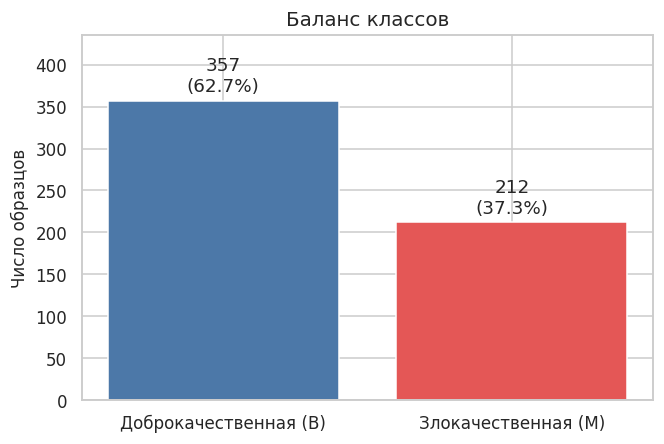

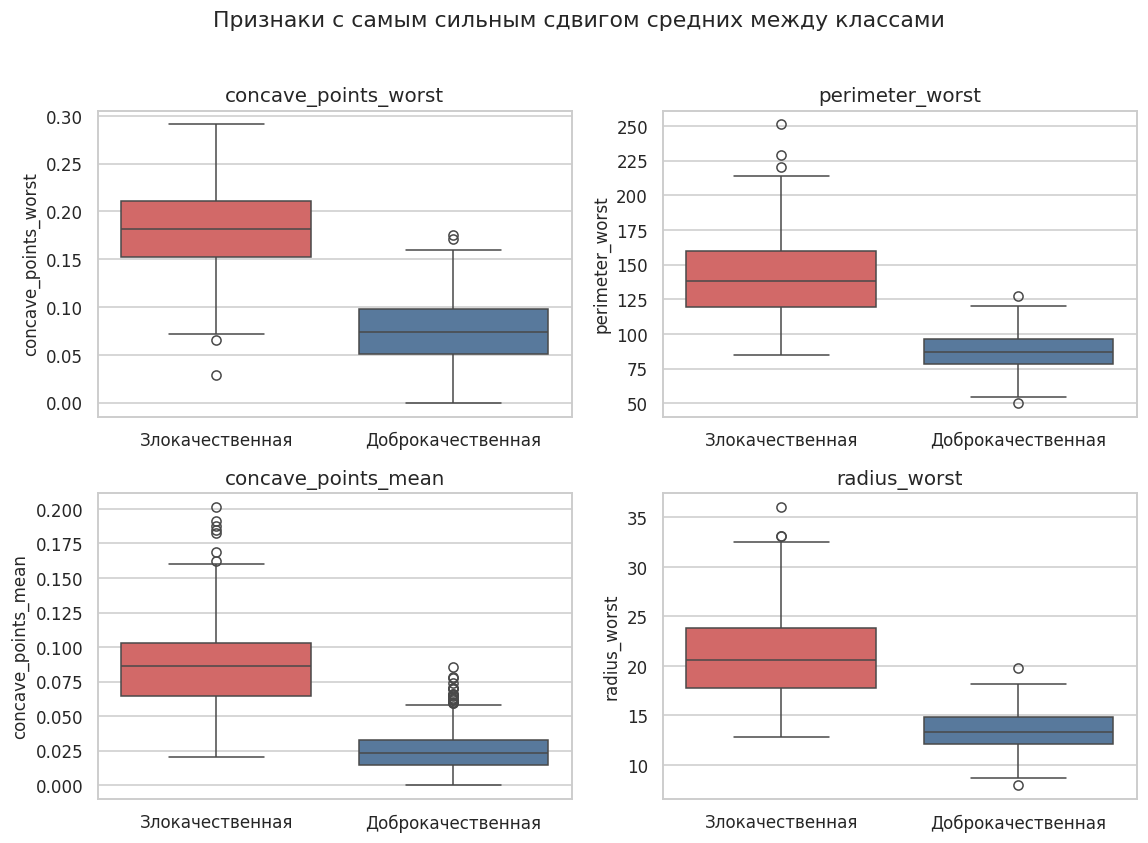

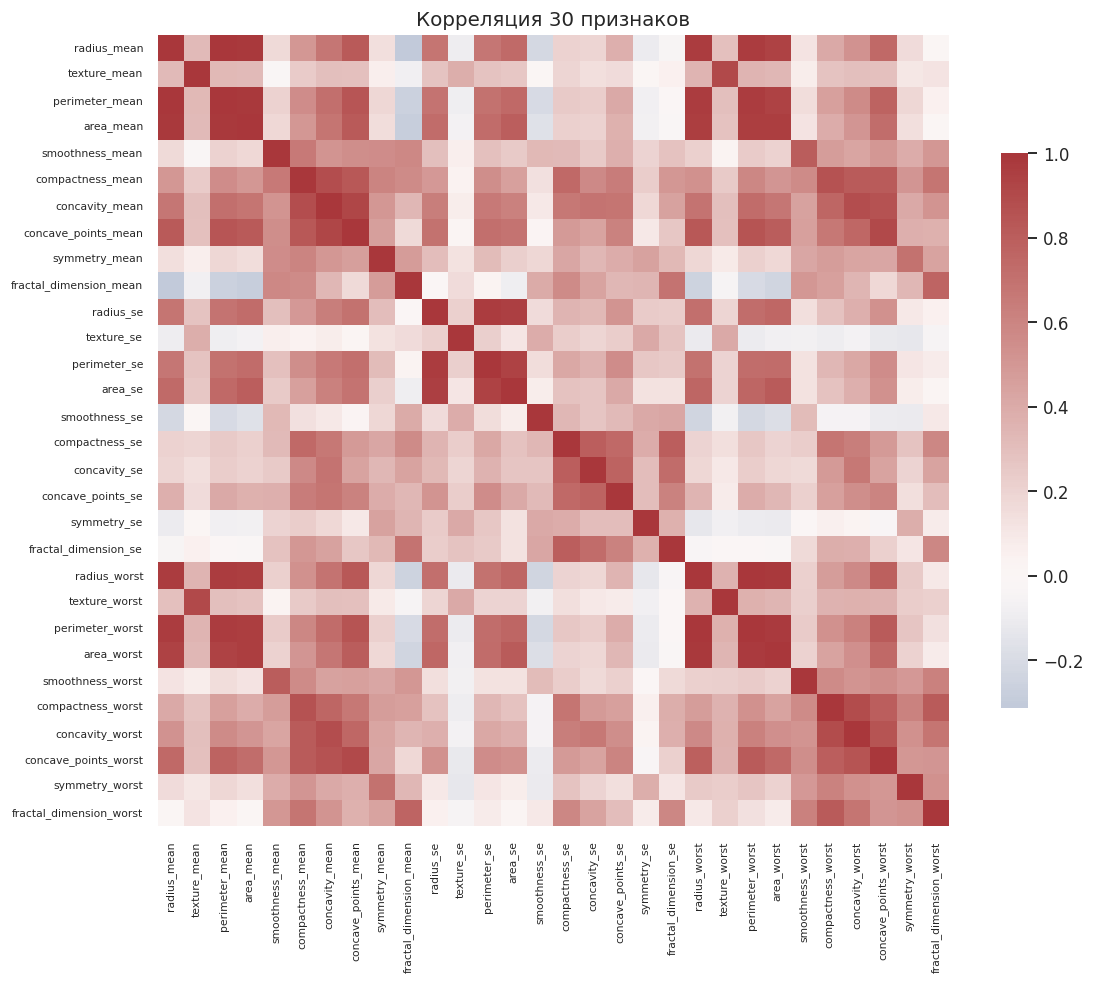

### Самые сильные попарные корреляции

,Признак 1,Признак 2,Корреляция
0,radius_mean,perimeter_mean,0.9979
1,radius_worst,perimeter_worst,0.9937
2,radius_mean,area_mean,0.9874
3,perimeter_mean,area_mean,0.9865
4,radius_worst,area_worst,0.9840
5,perimeter_worst,area_worst,0.9776
6,radius_se,perimeter_se,0.9728
7,perimeter_mean,perimeter_worst,0.9704



### Вывод по выбору и подготовке данных

В файле было 569 строк и 32 столбца. После очистки осталось **569 объектов и 30 признаков**. Пропущенных значений **0**, полных дубликатов строк **0**. Заполнять пропуски и выбрасывать объекты не пришлось.

Столбец `id` удалён. Это номер образца, а не свойство клетки: если оставить его среди признаков, дерево или kNN могут запомнить конкретные номера, и качество на тесте ничего не скажет о биологии опухоли. Имена `concave points_*` приведены к `concave_points_*`. Цель перекодирована: злокачественная опухоль = 1 (212 объектов, 37.3%), доброкачественная = 0 (357 объектов, 62.7%). Доброкачественных случаев больше примерно в 1.68 раза. Перекос умеренный, но достаточный, чтобы Accuracy без Recall вводила в заблуждение.

Все 30 признаков числовые и неотрицательные. Масштабы при этом несопоставимы. `area_mean` лежит в диапазоне 143.5–2501.0, а `smoothness_mean` — в диапазоне 0.0526–0.1634. Расстояние в kNN, ширина поля в SVM и добавка к дисперсии в GaussianNB смотрят на абсолютную величину. Без приведения масштаба площадь задавит гладкость. Дерево решений сравнивает порог внутри одного столбца, поэтому монотонное масштабирование его разбиения не меняет. Стандартизация **не делается на всей таблице до разбиения**: среднее и дисперсия теста не должны попадать в обучающие параметры. Масштабировщик стоит внутри `Pipeline` и обучается только на обучающей части каждого фолда.

Крайние площади не удалялись. Большое ядро — типичная черта злокачественного класса, а не сбой прибора. Выкинуть такие строки значило бы специально ослабить самый понятный сигнал.

Модуль наибольшего Cohen's d больше 1.5: даже один признак сильно разводит классы. Линейные методы здесь имеют хорошие шансы, потому что сигнал не спрятан в сложной комбинации слабых признаков. Сильнее всего классы разведены по признакам: concave_points_worst (d = 2.60, среднее B = 0.074, среднее M = 0.182; concave_points_worst — число вогнутых участков, среднее трёх наибольших значений); perimeter_worst (d = 2.37, среднее B = 87.006, среднее M = 141.370; perimeter_worst — периметр ядра, среднее трёх наибольших значений); concave_points_mean (d = 2.33, среднее B = 0.026, среднее M = 0.088; concave_points_mean — число вогнутых участков, среднее по ядрам на снимке). Ящики с усами показывают сдвиг, но и перекрытие: по одному признаку идеальной границы нет, хвосты классов заходят друг в друга. Слабее всего различают классы fractal_dimension_mean (d = -0.03); texture_se (d = -0.02); symmetry_se (d = -0.01). Эти столбцы оставлены в матрице, чтобы все методы сравнивались на одном и том же полном наборе, а не на индивидуально подобранном подмножестве.

Радиус, периметр и площадь описывают один и тот же размер. Корреляция `radius_mean` и `perimeter_mean` равна 0.998, `radius_mean` и `area_mean` — 0.987. Для дерева это просто три похожих кандидата на расщепление. Для наивного Байеса это нарушение независимости: один и тот же размер будет учтён трижды. Для LDA это почти вырожденная ковариационная матрица, поэтому ниже отдельно проверяется сжатие (`shrinkage`).


In [2]:
df = raw.copy()
df.columns = [c.strip().replace(" ", "_") for c in df.columns]
df = df.drop(columns=["id"])
df["diagnosis"] = df["diagnosis"].map({"M": 1, "B": 0}).astype(int)

feature_cols = [c for c in df.columns if c != "diagnosis"]
X = df[feature_cols].copy()
y = df["diagnosis"].copy()

n = len(df)
n_m = int(y.sum())
n_b = n - n_m
na_total = int(df.isna().sum().sum())
n_dup = int(df.duplicated().sum())

assert set(y.unique()) == {0, 1}
assert na_total == 0
assert X.shape == (569, 30)

base_meaning = {
    "radius": "средний радиус ядра",
    "texture": "разброс яркости пикселей",
    "perimeter": "периметр ядра",
    "area": "площадь ядра",
    "smoothness": "гладкость контура",
    "compactness": "компактность контура",
    "concavity": "выраженность вогнутостей",
    "concave_points": "число вогнутых участков",
    "symmetry": "симметрия ядра",
    "fractal_dimension": "фрактальная изрезанность контура",
}
suffix_meaning = {
    "mean": "среднее по ядрам на снимке",
    "se": "стандартная ошибка внутри снимка",
    "worst": "среднее трёх наибольших значений",
}

def explain_feature(name):
    for suffix in ("_worst", "_mean", "_se"):
        if name.endswith(suffix):
            base = name[: -len(suffix)]
            key = suffix[1:]
            return (
                f"{name} — {base_meaning.get(base, base)}, "
                f"{suffix_meaning[key]}"
            )
    return name

effect_rows = []
for col in feature_cols:
    x1 = X.loc[y == 1, col]
    x0 = X.loc[y == 0, col]
    pooled = np.sqrt((x1.var(ddof=1) + x0.var(ddof=1)) / 2)
    effect_rows.append(
        {
            "Признак": col,
            "Пояснение": explain_feature(col),
            "Cohen_d": (x1.mean() - x0.mean()) / pooled,
            "Среднее B": x0.mean(),
            "Среднее M": x1.mean(),
        }
    )
effect = pd.DataFrame(effect_rows).sort_values("Cohen_d", key=lambda s: s.abs(), ascending=False)
effect_view = effect.copy()
effect_view["Cohen_d"] = effect_view["Cohen_d"].round(3)
effect_view["Среднее B"] = effect_view["Среднее B"].round(3)
effect_view["Среднее M"] = effect_view["Среднее M"].round(3)

desc = X.describe().T[["min", "max", "mean", "std"]]
display(Markdown("### Числовой профиль признаков"))
display(desc.round(4))
display(Markdown(
    "Cohen's d — на сколько общих стандартных отклонений среднее злокачественного класса "
    "сдвинуто относительно доброкачественного. Знак плюс значит, что у злокачественных среднее больше. "
    "Ниже признаки отсортированы по модулю этого сдвига."
))
display(effect_view.reset_index(drop=True))

fig, ax = plt.subplots(figsize=(6.2, 4.2))
counts = pd.Series({"Доброкачественная (B)": n_b, "Злокачественная (M)": n_m})
bars = ax.bar(counts.index, counts.values, color=["#4C78A8", "#E45756"])
for bar, value in zip(bars, counts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 6,
        f"{value}\n({value / n:.1%})",
        ha="center",
        va="bottom",
    )
ax.set_ylim(0, max(counts.values) * 1.22)
ax.set_ylabel("Число образцов")
ax.set_title("Баланс классов")
fig.tight_layout()
plt.show()

top_features = effect["Признак"].head(4).tolist()
plot_df = df.copy()
plot_df["Класс"] = plot_df["diagnosis"].map({0: "Доброкачественная", 1: "Злокачественная"})
fig, axes = plt.subplots(2, 2, figsize=(10.5, 7.5))
for ax, col in zip(axes.ravel(), top_features):
    sns.boxplot(
        data=plot_df,
        x="Класс",
        y=col,
        hue="Класс",
        palette={"Доброкачественная": "#4C78A8", "Злокачественная": "#E45756"},
        legend=False,
        ax=ax,
    )
    ax.set_title(col)
    ax.set_xlabel("")
fig.suptitle("Признаки с самым сильным сдвигом средних между классами", y=1.02)
fig.tight_layout()
plt.show()

corr = X.corr()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    corr,
    cmap="vlag",
    center=0,
    square=True,
    ax=ax,
    cbar_kws={"shrink": 0.7},
    xticklabels=True,
    yticklabels=True,
)
ax.tick_params(labelsize=7)
ax.set_title("Корреляция 30 признаков")
fig.tight_layout()
plt.show()

pairs = (
    corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    .stack()
    .dropna()
    .sort_values(ascending=False)
)
pair_table = pairs.head(8).rename("Корреляция").reset_index()
pair_table.columns = ["Признак 1", "Признак 2", "Корреляция"]
display(Markdown("### Самые сильные попарные корреляции"))
display(pair_table.round(4))

top3 = effect.head(3)
weak3 = effect.tail(3)
top3_text = "; ".join(
    f"{row['Признак']} (d = {row['Cohen_d']:.2f}, среднее B = {row['Среднее B']:.3f}, "
    f"среднее M = {row['Среднее M']:.3f}; {row['Пояснение']})"
    for _, row in top3.iterrows()
)
weak3_text = "; ".join(
    f"{row['Признак']} (d = {row['Cohen_d']:.2f})" for _, row in weak3.iterrows()
)
radius_perimeter = float(corr.loc["radius_mean", "perimeter_mean"])
radius_area = float(corr.loc["radius_mean", "area_mean"])
area_min, area_max = float(X["area_mean"].min()), float(X["area_mean"].max())
sm_min, sm_max = float(X["smoothness_mean"].min()), float(X["smoothness_mean"].max())
max_d = float(effect["Cohen_d"].abs().max())

separation_comment = (
    "Модуль наибольшего Cohen's d больше 1.5: даже один признак сильно разводит классы. "
    "Линейные методы здесь имеют хорошие шансы, потому что сигнал не спрятан в сложной комбинации слабых признаков."
    if max_d > 1.5
    else
    "Сдвиг средних умеренный: одному признаку классы не отдать, и качество будет сильнее зависеть от того, как метод собирает признаки вместе."
)

prep_text = f'''
### Вывод по выбору и подготовке данных

В файле было {raw.shape[0]} строк и {raw.shape[1]} столбца. После очистки осталось **{n} объектов и {X.shape[1]} признаков**. Пропущенных значений **{na_total}**, полных дубликатов строк **{n_dup}**. Заполнять пропуски и выбрасывать объекты не пришлось.

Столбец `id` удалён. Это номер образца, а не свойство клетки: если оставить его среди признаков, дерево или kNN могут запомнить конкретные номера, и качество на тесте ничего не скажет о биологии опухоли. Имена `concave points_*` приведены к `concave_points_*`. Цель перекодирована: злокачественная опухоль = 1 ({n_m} объектов, {n_m / n:.1%}), доброкачественная = 0 ({n_b} объектов, {n_b / n:.1%}). Доброкачественных случаев больше примерно в {n_b / n_m:.2f} раза. Перекос умеренный, но достаточный, чтобы Accuracy без Recall вводила в заблуждение.

Все 30 признаков числовые и неотрицательные. Масштабы при этом несопоставимы. `area_mean` лежит в диапазоне {area_min:.1f}–{area_max:.1f}, а `smoothness_mean` — в диапазоне {sm_min:.4f}–{sm_max:.4f}. Расстояние в kNN, ширина поля в SVM и добавка к дисперсии в GaussianNB смотрят на абсолютную величину. Без приведения масштаба площадь задавит гладкость. Дерево решений сравнивает порог внутри одного столбца, поэтому монотонное масштабирование его разбиения не меняет. Стандартизация **не делается на всей таблице до разбиения**: среднее и дисперсия теста не должны попадать в обучающие параметры. Масштабировщик стоит внутри `Pipeline` и обучается только на обучающей части каждого фолда.

Крайние площади не удалялись. Большое ядро — типичная черта злокачественного класса, а не сбой прибора. Выкинуть такие строки значило бы специально ослабить самый понятный сигнал.

{separation_comment} Сильнее всего классы разведены по признакам: {top3_text}. Ящики с усами показывают сдвиг, но и перекрытие: по одному признаку идеальной границы нет, хвосты классов заходят друг в друга. Слабее всего различают классы {weak3_text}. Эти столбцы оставлены в матрице, чтобы все методы сравнивались на одном и том же полном наборе, а не на индивидуально подобранном подмножестве.

Радиус, периметр и площадь описывают один и тот же размер. Корреляция `radius_mean` и `perimeter_mean` равна {radius_perimeter:.3f}, `radius_mean` и `area_mean` — {radius_area:.3f}. Для дерева это просто три похожих кандидата на расщепление. Для наивного Байеса это нарушение независимости: один и тот же размер будет учтён трижды. Для LDA это почти вырожденная ковариационная матрица, поэтому ниже отдельно проверяется сжатие (`shrinkage`).
'''
display(Markdown(prep_text))

## 3. Разбиение выборки

Данные делятся один раз: 80% — обучение, 20% — тест. Параметр `stratify=y` сохраняет долю злокачественных случаев в обеих частях. `random_state=42` фиксирует состав групп.

Тестовая часть не участвует ни в каких сетках. Гиперпараметры выбираются только по обучающей части, стратифицированной кросс-валидацией на 5 фолдах (`shuffle=True`, тот же seed). В каждом фолде конвейер заново обучает масштабировщик. Так среднее признака, посчитанное по проверяемому фолду, не протекает в модель.

Пять фолдов на 455 объектах дают около 90 объектов в проверке. Это немного, поэтому у среднего AUC дальше приводится стандартное отклонение по фолдам. Если выигрыш сетки меньше этого разброса, он не считается надёжным улучшением.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

def split_line(name, target):
    return {
        "Выборка": name,
        "Объектов": int(len(target)),
        "Злокачественных": int(target.sum()),
        "Доброкачественных": int((target == 0).sum()),
        "Доля злокачественных": float(target.mean()),
    }

split_table = pd.DataFrame(
    [
        split_line("Вся таблица", y),
        split_line("Обучение", y_train),
        split_line("Тест", y_test),
    ]
)
display(split_table.round(4))

n_test = int(len(y_test))
n_pos_test = int(y_test.sum())
n_neg_test = n_test - n_pos_test
majority_acc = n_neg_test / n_test
recall_unit = 1 / n_pos_test
acc_unit = 1 / n_test

split_text = f'''
### Вывод по разбиению

В обучении **{len(y_train)}** объектов, из них злокачественных **{int(y_train.sum())}** ({y_train.mean():.1%}). В тесте **{n_test}** объектов, злокачественных **{n_pos_test}** ({y_test.mean():.1%}), доброкачественных **{n_neg_test}**. Доли близки к исходным {y.mean():.1%}: стратификация сработала, модель не получит тест с другой базовой частотой болезни.

Тест маленький. Один неверный объект меняет Accuracy на {acc_unit:.3f}, то есть на {acc_unit * 100:.2f} процентного пункта. Один пропущенный злокачественный случай меняет Recall на {recall_unit:.3f}. Разница методов в третьем знаке после запятой — это часто один пациент, а не устойчивое превосходство алгоритма.

Если на тесте всегда отвечать «доброкачественная», Accuracy будет {majority_acc:.3f}, Precision по злокачественному классу не определена осмысленно (тревог нет), Recall равен нулю. Любая модель в финальной таблице обязана быть выше этой полки по Accuracy и, главное, находить злокачественные случаи. Подбор параметров эту тестовую полку не видит: сетка смотрит только на пять фолдов обучения.
'''
display(Markdown(split_text))

,Выборка,Объектов,Злокачественных,Доброкачественных,Доля злокачественных
0,Вся таблица,569,212,357,0.3726
1,Обучение,455,170,285,0.3736
2,Тест,114,42,72,0.3684



### Вывод по разбиению

В обучении **455** объектов, из них злокачественных **170** (37.4%). В тесте **114** объектов, злокачественных **42** (36.8%), доброкачественных **72**. Доли близки к исходным 37.3%: стратификация сработала, модель не получит тест с другой базовой частотой болезни.

Тест маленький. Один неверный объект меняет Accuracy на 0.009, то есть на 0.88 процентного пункта. Один пропущенный злокачественный случай меняет Recall на 0.024. Разница методов в третьем знаке после запятой — это часто один пациент, а не устойчивое превосходство алгоритма.

Если на тесте всегда отвечать «доброкачественная», Accuracy будет 0.632, Precision по злокачественному классу не определена осмысленно (тревог нет), Recall равен нулю. Любая модель в финальной таблице обязана быть выше этой полки по Accuracy и, главное, находить злокачественные случаи. Подбор параметров эту тестовую полку не видит: сетка смотрит только на пять фолдов обучения.


## 4. Методы классификации

Ниже — идея каждого метода, его предпосылки именно на этих данных и параметры, которые будут перебираться. Формулы даны в том виде, в каком по ним потом читаются графики. Один и тот же объект описан вектором \(x\) из 30 признаков, ответ \(y \in \{0, 1\}\).

### 4.1. Наивный байесовский классификатор

Классификатор выбирает класс с большей апостериорной вероятностью. По формуле Байеса она пропорциональна \(P(y)\,P(x \mid y)\). «Наивность» в том, что признаки считаются условно независимыми при известном классе, и правдоподобие раскладывается в произведение одномерных плотностей. На наших данных это заведомо приближение: радиус, периметр и площадь зависимы. Метод всё равно полезен как быстрая базовая модель и как способ увидеть, насколько сильно нарушение независимости бьёт по качеству.

Четыре класса в scikit-learn отличаются тем, каким распределением они описывают \(P(x_j \mid y)\).

**GaussianNB** считает каждый признак нормальным внутри класса. Оцениваются среднее и дисперсия. Параметр `var_smoothing` добавляет ко всем дисперсиям долю самой большой дисперсии среди признаков. Малая добавка страхует от нулевой дисперсии. Большая добавка раздувает распределения, классы начинают сильно перекрываться, AUC падает. Добавка одна на все признаки и привязана к максимальной дисперсии. Пока площадь измеряется сотнями, а гладкость — сотыми, одна и та же добавка относительно огромна для гладкости и ничтожна для площади. Поэтому для GaussianNB сравниваются сырые признаки и `StandardScaler`.

**MultinomialNB** выведен для неотрицательных счётчиков: признак — это число исходов одной мультиномиальной схемы, `alpha` — сглаживание Лапласа, чтобы нулевой счётчик не обращал вероятность в ноль. Измерения ядра счётчиками не являются. Метод всё равно строится, потому что задание требует этот вариант, но только на неотрицательных числах. `StandardScaler` здесь недопустим: отрицательные значения ломают оценку. Сравниваются исходный масштаб и `MinMaxScaler` на отрезок [0, 1]. В исходном масштабе площадь даёт почти всю «массу» мультиномиального вектора и может заслонить слабые признаки.

**ComplementNB** оценивает параметры по объектам всех остальных классов, а не по объектам своего класса. Так сделано для несбалансированных текстовых задач, чтобы редкий класс не получал слишком шумные веса. Ограничение то же: признаки неотрицательны, `alpha` сглаживает нули. При долях 63/37 выигрыш над MultinomialNB не гарантирован; это проверяется экспериментом, а не считается заранее известным.

**BernoulliNB** видит только нули и единицы: признак либо «есть», либо «нет». Непрерывную величину нужно обрезать порогом `binarize`. Порог 0 на сырых данных почти ничего не режет: радиус и площадь и так всегда больше нуля, и векторы становятся похожими наборами единиц. Честный порог ставится после `MinMaxScaler`. Даже удачный порог выбрасывает информацию «насколько больше», поэтому Бернулли на этих данных обычно слабее гауссовского варианта. Это ожидаемая плата за бинаризацию, и её нужно увидеть в цифрах.

### 4.2. Дерево решений

Дерево на каждом шаге выбирает признак и порог, которые сильнее всего уменьшают неоднородность узла. Неоднородность измеряется критерием Джини или энтропией. Прогноз листа — класс большинства в листе, вероятность — доля класса в листе.

`max_depth` ограничивает число последовательных вопросов. Глубина 1–2 на 30 признаках почти наверняка недообучает. Глубина без ограничения при `min_samples_leaf=1` растит листья из одного объекта: на обучении AUC стремится к единице, на новом фолде дерево уже подгоняется под случайные пороги. `min_samples_leaf` запрещает такие листья. Критерий Джини или энтропия по-разному штрафует смесь классов; когда классы грубо разделимы уже по размеру ядра, смена критерия часто даёт маленький прирост. Масштабирование дереву не нужно.

Дерево хорошо показывает взаимодействие «если ядро крупное и контур изрезан», но полученная граница кусочно-постоянная и чувствительна к составу выборки.

### 4.3. Линейный дискриминантный анализ

LDA ищет линейную проекцию, на которой средние классов далеки друг от друга, а разброс внутри класса мал. В бинарной задаче это одна ось и порог на ней. Предполагается, что классы примерно гауссовские и делят общую ковариационную матрицу. Вторая часть на наших данных хрупкая: радиус, периметр и площадь почти линейно зависимы, эмпирическая ковариация плохо обусловлена.

`shrinkage` подмешивает ковариацию к диагональной матрице. Ноль означает «верить выборочной ковариации», единица — «считать признаки некоррелированными и смотреть только на дисперсии». Промежуточное значение — компромисс. Значение `'auto'` в scikit-learn выбирает коэффициент по лемме Ледойта–Вольфа. Сжатие умеют солверы `lsqr` и `eigen`. Солвер `svd` сжатие игнорирует и служит базой без регуляризации.

Сжатие зависит от масштаба: диагональная цель считает признаки равноправными только если они заранее приведены к одной дисперсии. Поэтому LDA стоит после `StandardScaler`. Без сжатия сам дискриминант к невырожденному линейному пересчёту признаков устойчивее; это будет видно по сравнению `svd` на сырых и на стандартизованных данных.

### 4.4. Метод опорных векторов

SVM строит границу, которая максимизирует полосу между классами. Объекты на краю полосы — опорные векторы. Параметр `C` — плата за попадание объекта не на свою сторону. Малый `C` разрешает широкую полосу и недообучение. Большой `C` прижимает границу к отдельным точкам и может запомнить шум.

Линейное ядро — одна гиперплоскость. Ядро RBF строит границу из гауссовых «шапок» вокруг опорных векторов. `gamma` задаёт узость шапки: большая gamma даёт очень локальные всплески и переобучение, малая — слишком гладкую функцию, похожую на линейную.

Признаки перед SVM стандартизируются. Иначе член площади в скалярном произведении на порядки больше члена гладкости, и полоса определяется почти только размером. `class_weight='balanced'` увеличивает штраф за ошибку на более редком злокачественном классе и обычно поднимает Recall ценой лишних тревог.

Перебор идёт по функции решения `decision_function`: для AUC-ROC важна сортировка объектов, а не калиброванная вероятность. У выбранной в финал модели вероятности достраиваются калибровкой Платта (`probability=True`), чтобы порог `predict` и ROC опирались на одну и ту же шкалу. Сама сетка эту калибровку не крутит.

### 4.5. Метод k ближайших соседей

kNN не оценивает параметры распределения. Новый объект получает класс большинства среди k ближайших обучающих объектов. При k = 1 ответ копирует одного соседа: на обучении ошибок нет, на тесте один шумный сосед ломает прогноз. При большом k голос усредняется. Поскольку злокачественных меньше 40%, слишком большое k стягивает оценку вероятности к базовой частоте, и при пороге 0.5 Recall злокачественных падает, хотя ранжирование (AUC) ещё может оставаться хорошим. Поэтому для kNN на графике будут и AUC, и Recall.

`weights='distance'` даёт ближнему соседу больший голос, чем дальнему. `uniform` считает всех k соседей равными. При k = 1 эти два режима совпадают. Метрика `euclidean` квадратично копит расхождения по координатам, `manhattan` складывает модули. Без стандартизации обе метрики почти сводятся к разнице площадей.

### Что именно будет перебираться

| Метод | Что меняется | Что должно быть видно на графике |
|---|---|---|
| GaussianNB | `var_smoothing`, сырой масштаб против StandardScaler | падение AUC при слишком сильном сглаживании |
| MultinomialNB | `alpha`, сырой масштаб против MinMax | влияние крупных признаков и силы сглаживания |
| ComplementNB | `alpha`, сырой масштаб против MinMax | есть ли выигрыш от дополнения класса |
| BernoulliNB | порог бинаризации, `alpha` | провал на крайних порогах, где векторы вырождаются |
| Дерево | глубина, минимум объектов в листе, критерий | рост разрыва train/validation с глубиной |
| LDA | `svd` против `lsqr` + `shrinkage` | помогает ли сжатие при коррелирующих размерах |
| SVM | `C`, ядро, `gamma`, `class_weight` | недообучение при малом C и узких RBF |
| kNN | число соседей, веса, метрика расстояния | идеал на k = 1 и просадка Recall при большом k |

### Правило выбора точки на сетке

Для каждой конфигурации считается среднее и стандартное отклонение по 5 фолдам. Основной показатель — AUC-ROC. Если несколько точек отстают от лучшего среднего AUC не больше чем на 0.005, берётся точка с меньшим разрывом между AUC на обучении внутри фолда и AUC на проверке. На плоской вершине это отбрасывает более переобученный вариант, которому просто повезло со средним. При равном разрыве предпочитается больший F1. Тест в этом выборе не участвует.

In [4]:
CV = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)
SCORING = {
    "roc_auc": "roc_auc",
    "f1": "f1",
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": "recall",
}

best_configs = {}
tuning_summary = {}


def format_param(value):
    if value is None:
        return "None"
    if isinstance(value, (bool, np.bool_)):
        return str(bool(value))
    if isinstance(value, (int, np.integer)):
        return str(int(value))
    if isinstance(value, (float, np.floating)):
        value = float(value)
        if value == 0:
            return "0"
        if abs(value) < 0.01:
            return f"{value:.0e}"
        return f"{value:g}"
    return str(value)


def evaluate_cv(estimator, X, y):
    result = cross_validate(
        estimator,
        X,
        y,
        cv=CV,
        scoring=SCORING,
        n_jobs=1,
        return_train_score=True,
        error_score="raise",
    )
    out = {}
    for key in SCORING:
        out[key] = float(result[f"test_{key}"].mean())
        out[f"{key}_std"] = float(result[f"test_{key}"].std())
        out[f"{key}_train"] = float(result[f"train_{key}"].mean())
    return out


def select_best(frame):
    pool = frame.copy()
    best_auc = pool["roc_auc"].max()
    pool = pool[pool["roc_auc"] >= best_auc - 0.005].copy()
    pool["gap"] = pool["roc_auc_train"] - pool["roc_auc"]
    pool = pool.sort_values(["gap", "roc_auc", "f1"], ascending=[True, False, False])
    return pool.iloc[0]


def interpret_sweep(frame, param_name, selected):
    max_row = frame.sort_values(["roc_auc", "f1"], ascending=False).iloc[0]
    worst = frame.sort_values(["roc_auc", "f1"], ascending=True).iloc[0]
    spread = float(max_row["roc_auc"] - worst["roc_auc"])
    near = frame[frame["roc_auc"] >= float(max_row["roc_auc"]) - 0.005]
    parts = []
    parts.append(
        f"В финал по правилу из раздела 4 уходит `{param_name}` = **{selected['param_label']}**. "
        f"На кросс-валидации AUC-ROC = {selected['roc_auc']:.4f} ± {selected['roc_auc_std']:.4f}, "
        f"F1 = {selected['f1']:.4f}, Precision = {selected['precision']:.4f}, "
        f"Recall = {selected['recall']:.4f}, Accuracy = {selected['accuracy']:.4f}."
    )
    parts.append(
        f"Худшая точка этой сетки — `{param_name}` = {worst['param_label']} "
        f"(AUC-ROC = {worst['roc_auc']:.4f}). Размах AUC-ROC равен {spread:.4f}."
    )
    if spread < 0.01:
        parts.append(
            "Размах меньше 0.01. В исследованном диапазоне параметр почти не двигает качество: "
            f"сдвиг сетки сопоставим со стандартным отклонением фолдов в выбранной точке "
            f"({selected['roc_auc_std']:.4f}) или меньше его. Метод здесь устойчив."
        )
    else:
        parts.append(
            "Размах больше 0.01, значит параметр действительно меняет качество. "
            "Значение по умолчанию на этих данных нужно проверять, а не принимать на веру."
        )
    if spread < float(selected["roc_auc_std"]):
        parts.append(
            "Размах сетки меньше стандартного отклонения по фолдам. "
            "Даже если средние чуть отличаются, объявить одну точку победителем по существу нельзя: фолды шумят сильнее, чем сама настройка."
        )
    if len(near) > 1:
        labels = ", ".join(near["param_label"].astype(str).tolist()[:8])
        extra = "" if len(near) <= 8 else f" и ещё {len(near) - 8}"
        parts.append(
            f"Почти тот же AUC-ROC (отставание от максимума не больше 0.005) дают: {labels}{extra}. "
            "Вершина сетки плоская."
        )
    if selected["param_label"] != max_row["param_label"]:
        auc_delta = float(max_row["roc_auc"] - selected["roc_auc"])
        gap_selected = float(selected["roc_auc_train"] - selected["roc_auc"])
        gap_max = float(max_row["roc_auc_train"] - max_row["roc_auc"])
        if auc_delta < 0.0005 and abs(gap_selected - gap_max) < 0.0005:
            parts.append(
                f"Точка формального максимума ({max_row['param_label']}) и выбранная точка "
                "совпадают до четвёртого знака и по AUC-ROC, и по разрыву между обучением и проверкой. "
                "На такой полке конкретное значение параметра не является отдельным результатом: "
                "годится любая точка из перечисленных выше."
            )
        else:
            parts.append(
                f"Формальный максимум среднего AUC-ROC находится в точке {max_row['param_label']} "
                f"({max_row['roc_auc']:.4f}). Выбранная точка уступает ему на {auc_delta:.4f}, "
                f"но разрыв обучение/проверка у неё меньше "
                f"({gap_selected:.4f} против {gap_max:.4f}). "
                "На плоской вершине оставлен более устойчивый вариант."
            )
    gap = float(selected["roc_auc_train"] - selected["roc_auc"])
    parts.append(
        f"В выбранной точке AUC-ROC на обучающей части фолда равен {selected['roc_auc_train']:.4f}, "
        f"на проверочной — {selected['roc_auc']:.4f}, разрыв {gap:.4f}."
    )
    if gap > 0.05:
        parts.append(
            "Разрыв больше 0.05: модель слишком точно запоминает обучающие объекты фолда. "
            "Это аргумент не увеличивать сложность дальше, даже если соседняя точка сетки выглядит привлекательно по одному среднему."
        )
    else:
        parts.append("Разрыв между обучением и проверкой небольшой, явного переобучения в выбранной точке нет.")
    return "\n\n".join(parts)


def plot_lines(frame, group_col, group_order, xlabel, title, ylabel="AUC-ROC", metric="roc_auc"):
    fig, ax = plt.subplots(figsize=(8.2, 4.6))
    for group in group_order:
        sub = frame[frame[group_col] == group]
        x = np.arange(len(sub))
        ax.plot(x, sub[metric], marker="o", label=str(group))
        if metric == "roc_auc" and f"{metric}_std" in sub.columns:
            ax.fill_between(
                x,
                sub[metric] - sub[f"{metric}_std"],
                sub[metric] + sub[f"{metric}_std"],
                alpha=0.12,
            )
    ax.set_xticks(range(len(sub)))
    ax.set_xticklabels(sub["param_label"], rotation=45, ha="right")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend(title="")
    fig.tight_layout()
    plt.show()


def make_gaussian(var_smoothing=1e-9, scale=True):
    clf = GaussianNB(var_smoothing=float(var_smoothing))
    if scale:
        return Pipeline([("scaler", StandardScaler()), ("clf", clf)])
    return clf


def make_multinomial(alpha=1.0, scale=True):
    clf = MultinomialNB(alpha=float(alpha))
    if scale:
        return Pipeline([("scaler", MinMaxScaler()), ("clf", clf)])
    return clf


def make_complement(alpha=1.0, scale=True):
    clf = ComplementNB(alpha=float(alpha))
    if scale:
        return Pipeline([("scaler", MinMaxScaler()), ("clf", clf)])
    return clf


def make_bernoulli(alpha=1.0, threshold=0.5, scale=True):
    clf = BernoulliNB(alpha=float(alpha), binarize=float(threshold))
    if scale:
        return Pipeline([("scaler", MinMaxScaler()), ("clf", clf)])
    return clf


def make_tree(max_depth=None, min_samples_leaf=1, criterion="gini"):
    return DecisionTreeClassifier(
        max_depth=max_depth,
        min_samples_leaf=int(min_samples_leaf),
        criterion=criterion,
        random_state=RANDOM_STATE,
    )


def make_lda(solver="svd", shrinkage=None, scale=True):
    kwargs = {"solver": solver}
    if shrinkage is not None:
        kwargs["shrinkage"] = shrinkage
    clf = LinearDiscriminantAnalysis(**kwargs)
    if scale:
        return Pipeline([("scaler", StandardScaler()), ("clf", clf)])
    return clf


def make_svm(C=1.0, kernel="rbf", gamma="scale", class_weight=None, probability=False, scale=True):
    clf = SVC(
        C=float(C),
        kernel=kernel,
        gamma="scale" if kernel == "linear" else gamma,
        class_weight=class_weight,
        probability=probability,
        random_state=RANDOM_STATE,
    )
    if scale:
        return Pipeline([("scaler", StandardScaler()), ("clf", clf)])
    return clf


def make_knn(n_neighbors=5, weights="uniform", metric="euclidean", scale=True):
    clf = KNeighborsClassifier(
        n_neighbors=int(n_neighbors),
        weights=weights,
        metric=metric,
    )
    if scale:
        return Pipeline([("scaler", StandardScaler()), ("clf", clf)])
    return clf


FACTORIES = {
    "gaussian": make_gaussian,
    "multinomial": make_multinomial,
    "complement": make_complement,
    "bernoulli": make_bernoulli,
    "tree": make_tree,
    "lda": make_lda,
    "svm": make_svm,
    "knn": make_knn,
}


def build(cfg, probability=False):
    params = dict(cfg["params"])
    if cfg["factory"] == "svm":
        params["probability"] = probability
    return FACTORIES[cfg["factory"]](**params)


def remember(name, factory, params, params_text, selected, default_auc, default_text):
    best_configs[name] = {
        "factory": factory,
        "params": params,
        "params_text": params_text,
        "cv_roc_auc": float(selected["roc_auc"]),
        "cv_roc_auc_std": float(selected["roc_auc_std"]),
    }
    tuning_summary[name] = {
        "Метод": name,
        "Конфигурация по умолчанию": default_text,
        "AUC по умолчанию": float(default_auc),
        "Выбранная конфигурация": params_text,
        "AUC после выбора": float(selected["roc_auc"]),
        "Прирост AUC": float(selected["roc_auc"] - default_auc),
    }

## 5. Настройка гиперпараметров

Каждый подраздел устроен одинаково. Сначала на обучающей выборке считается сетка, затем строится график зависимости качества от параметра, затем формулируется вывод: где качество стоит, где падает и какую конфигурацию забираем в финальное сравнение. Числа в выводах — средние по тем же пяти фолдам. Тестовая выборка по-прежнему не используется.

Полоса вокруг линии на графиках — одно стандартное отклонение по фолдам, где она показана.

### 5.1. GaussianNB

Перебирается `var_smoothing` от \(10^{-12}\) до \(1\) на логарифмической сетке, отдельно на сырых признаках и после `StandardScaler`. Значение по умолчанию в scikit-learn — \(10^{-9}\). Ожидание такое: на левом краю добавка к дисперсии ничтожна и модель живёт за счёт выборочных средних; на правом краю дисперсии раздуты, классы перекрываются. Стандартизация должна менять не форму гауссианы как таковую, а честность общей добавки `var_smoothing` между признаками разного масштаба.

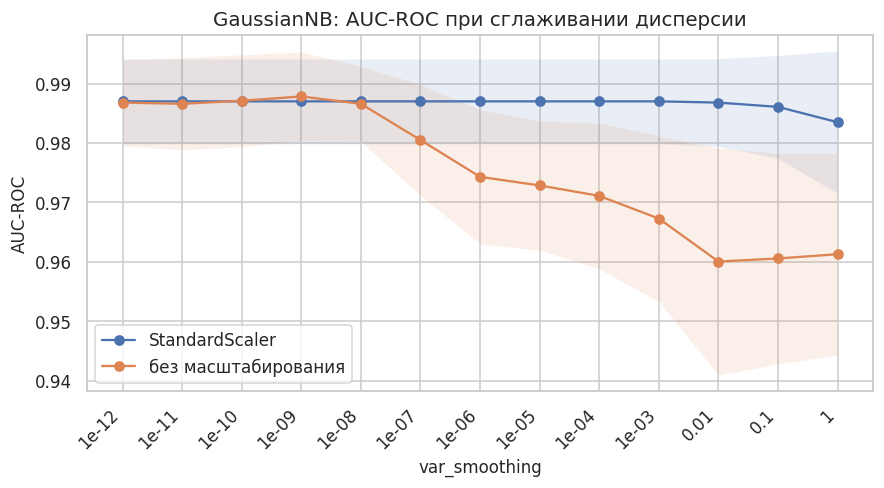


### Вывод по GaussianNB

В финал по правилу из раздела 4 уходит `var_smoothing` = **1e-03**. На кросс-валидации AUC-ROC = 0.9870 ± 0.0071, F1 = 0.9170, Precision = 0.9247, Recall = 0.9118, Accuracy = 0.9385.

Худшая точка этой сетки — `var_smoothing` = 1 (AUC-ROC = 0.9835). Размах AUC-ROC равен 0.0035.

Размах меньше 0.01. В исследованном диапазоне параметр почти не двигает качество: сдвиг сетки сопоставим со стандартным отклонением фолдов в выбранной точке (0.0071) или меньше его. Метод здесь устойчив.

Размах сетки меньше стандартного отклонения по фолдам. Даже если средние чуть отличаются, объявить одну точку победителем по существу нельзя: фолды шумят сильнее, чем сама настройка.

Почти тот же AUC-ROC (отставание от максимума не больше 0.005) дают: 1e-12, 1e-11, 1e-10, 1e-09, 1e-08, 1e-07, 1e-06, 1e-05 и ещё 5. Вершина сетки плоская.

Точка формального максимума (1e-12) и выбранная точка совпадают до четвёртого знака и по AUC-ROC, и по разрыву между обучением и проверкой. На такой полке конкретное значение параметра не является отдельным результатом: годится любая точка из перечисленных выше.

В выбранной точке AUC-ROC на обучающей части фолда равен 0.9888, на проверочной — 0.9870, разрыв 0.0018.

Разрыв между обучением и проверкой небольшой, явного переобучения в выбранной точке нет.

База для таблицы настройки — библиотечное `var_smoothing=1e-9` вместе со `StandardScaler`: AUC-ROC = 0.9870. Прирост выбранной точки относительно этой базы: +0.0000.

При значении по умолчанию 1e-9 стандартизация меняет AUC-ROC всего на -0.0008. Добавка к дисперсии настолько мала, что различие масштабов ещё не успевает её исказить. Лучшая сырая конфигурация достигает AUC-ROC 0.9871 при var_smoothing=1e-10. Лучшая стандартизованная — 0.9870. После подбора обе ветки выходят на одну полку. Решает не масштабирование само по себе, а чтобы сглаживание не было чрезмерным.

На стандартизованной ветке при самом слабом сглаживании (1e-12) AUC-ROC = 0.9870, при самом сильном (1) — 0.9835. Даже сильное сглаживание не обрушивает качество. Классы разведены по средним настолько, что точная дисперсия вторична.

В финальную таблицу идёт GaussianNB с параметрами `StandardScaler, var_smoothing=1e-03`. Предпосылка независимости по-прежнему нарушена корреляцией размера, поэтому модель трижды учитывает по сути один и тот же радиус. Это не мешает ей быть сильным ориентиром, если маргинальные распределения и так хорошо разделяют классы, но это предел метода: зависимости между признаками он не выучивает.


In [5]:
rows = []
for scale in (False, True):
    for var_smoothing in np.logspace(-12, 0, 13):
        metrics = evaluate_cv(make_gaussian(var_smoothing, scale=scale), X_train, y_train)
        rows.append(
            {
                "scale": scale,
                "group": "StandardScaler" if scale else "без масштабирования",
                "var_smoothing": float(var_smoothing),
                "param_label": format_param(var_smoothing),
                **metrics,
            }
        )
gaussian_df = pd.DataFrame(rows)
plot_lines(
    gaussian_df,
    "group",
    ["StandardScaler", "без масштабирования"],
    "var_smoothing",
    "GaussianNB: AUC-ROC при сглаживании дисперсии",
)

scaled = gaussian_df[gaussian_df["scale"]].copy()
selected = select_best(scaled)
default_row = scaled.loc[(scaled["var_smoothing"] - 1e-9).abs().idxmin()]
raw_default = gaussian_df[(~gaussian_df["scale"]) & ((gaussian_df["var_smoothing"] - 1e-9).abs() < 1e-15)].iloc[0]
raw_best = select_best(gaussian_df[~gaussian_df["scale"]].copy())

params = {"var_smoothing": float(selected["var_smoothing"]), "scale": True}
params_text = f"StandardScaler, var_smoothing={format_param(selected['var_smoothing'])}"
remember(
    "GaussianNB",
    "gaussian",
    params,
    params_text,
    selected,
    float(default_row["roc_auc"]),
    "StandardScaler, var_smoothing=1e-9",
)

scale_delta = float(default_row["roc_auc"] - raw_default["roc_auc"])
if abs(scale_delta) < 0.005:
    scale_comment = (
        f"При значении по умолчанию 1e-9 стандартизация меняет AUC-ROC всего на {scale_delta:+.4f}. "
        "Добавка к дисперсии настолько мала, что различие масштабов ещё не успевает её исказить."
    )
elif scale_delta > 0:
    scale_comment = (
        f"При том же var_smoothing=1e-9 StandardScaler поднимает AUC-ROC на {scale_delta:.4f} "
        f"(с {raw_default['roc_auc']:.4f} до {default_row['roc_auc']:.4f}). "
        "Без масштабирования максимальная дисперсия принадлежит площади, и общая добавка непропорционально раздувает дисперсию гладкости, симметрии и фрактальной размерности."
    )
else:
    scale_comment = (
        f"При var_smoothing=1e-9 сырые признаки дают AUC-ROC на {-scale_delta:.4f} выше стандартизованных "
        f"({raw_default['roc_auc']:.4f} против {default_row['roc_auc']:.4f}). "
        "Для финала всё равно оставлена стандартизация: на ней же выбрано сглаживание, и признаки входят в модель равноправно."
    )

best_raw_comment = (
    f"Лучшая сырая конфигурация достигает AUC-ROC {raw_best['roc_auc']:.4f} "
    f"при var_smoothing={raw_best['param_label']}. "
    f"Лучшая стандартизованная — {selected['roc_auc']:.4f}. "
)
if selected["roc_auc"] + 0.005 < raw_best["roc_auc"]:
    best_raw_comment += "Сырой масштаб формально сильнее, но отрыв небольшой, и в финал он не берётся: сравнение с SVM и kNN дальше идёт на стандартизованных признаках, а GaussianNB оставляем в том же конвейере."
elif raw_best["roc_auc"] + 0.005 < selected["roc_auc"]:
    best_raw_comment += "После подбора сглаживания стандартизованная модель всё ещё впереди. Масштаб здесь не косметика."
else:
    best_raw_comment += "После подбора обе ветки выходят на одну полку. Решает не масштабирование само по себе, а чтобы сглаживание не было чрезмерным."

right = scaled.iloc[-1]
left = scaled.iloc[0]
edge_comment = (
    f"На стандартизованной ветке при самом слабом сглаживании ({left['param_label']}) AUC-ROC = {left['roc_auc']:.4f}, "
    f"при самом сильном ({right['param_label']}) — {right['roc_auc']:.4f}. "
)
if right["roc_auc"] + 0.02 < selected["roc_auc"]:
    edge_comment += "Правый край сетки проседает: дисперсии становятся почти одинаково большими, и плотность класса перестаёт отличить крупное изрезанное ядро от мелкого гладкого."
else:
    edge_comment += "Даже сильное сглаживание не обрушивает качество. Классы разведены по средним настолько, что точная дисперсия вторична."

text = f'''
### Вывод по GaussianNB

{interpret_sweep(scaled, "var_smoothing", selected)}

База для таблицы настройки — библиотечное `var_smoothing=1e-9` вместе со `StandardScaler`: AUC-ROC = {default_row['roc_auc']:.4f}. Прирост выбранной точки относительно этой базы: {selected['roc_auc'] - default_row['roc_auc']:+.4f}.

{scale_comment} {best_raw_comment}

{edge_comment}

В финальную таблицу идёт GaussianNB с параметрами `{params_text}`. Предпосылка независимости по-прежнему нарушена корреляцией размера, поэтому модель трижды учитывает по сути один и тот же радиус. Это не мешает ей быть сильным ориентиром, если маргинальные распределения и так хорошо разделяют классы, но это предел метода: зависимости между признаками он не выучивает.
'''
display(Markdown(text))

### 5.2. MultinomialNB

`alpha` перебирается от 0.001 до 10. Две ветки предобработки: исходные неотрицательные измерения и `MinMaxScaler`. Отрицательные значения после `StandardScaler` в сетку не входят — на них мультиномиальная оценка не определена. Большой `alpha` стягивает вероятности признаков к равномерным и стирает различия классов. Масштаб решает другое: без MinMax площадь и периметр дают основную массу вектора, и модель почти не смотрит на гладкость и симметрию.

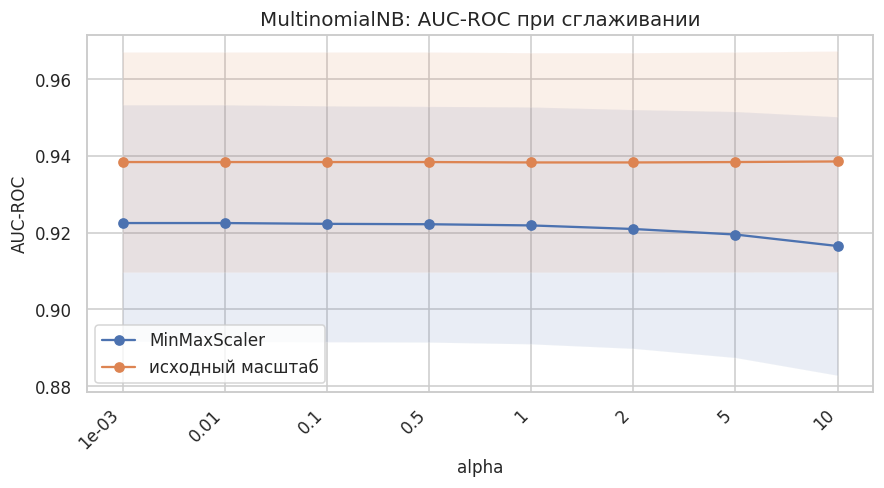


### Вывод по MultinomialNB

Сетка рассматривает и масштаб, и `alpha`. В финал по правилу из раздела 4 уходит `alpha` = **10**. На кросс-валидации AUC-ROC = 0.9385 ± 0.0288, F1 = 0.8463, Precision = 0.9423, Recall = 0.7706, Accuracy = 0.8967.

Худшая точка этой сетки — `alpha` = 1 (AUC-ROC = 0.9383). Размах AUC-ROC равен 0.0003.

Размах меньше 0.01. В исследованном диапазоне параметр почти не двигает качество: сдвиг сетки сопоставим со стандартным отклонением фолдов в выбранной точке (0.0288) или меньше его. Метод здесь устойчив.

Размах сетки меньше стандартного отклонения по фолдам. Даже если средние чуть отличаются, объявить одну точку победителем по существу нельзя: фолды шумят сильнее, чем сама настройка.

Почти тот же AUC-ROC (отставание от максимума не больше 0.005) дают: 1e-03, 0.01, 0.1, 0.5, 1, 2, 5, 10. Вершина сетки плоская.

В выбранной точке AUC-ROC на обучающей части фолда равен 0.9416, на проверочной — 0.9385, разрыв 0.0030.

Разрыв между обучением и проверкой небольшой, явного переобучения в выбранной точке нет.

За базу в сводной таблице взят осмысленный библиотечный вариант: MinMax и `alpha=1`, AUC-ROC = 0.9219. Выбранная конфигурация — `исходный масштаб, alpha=10`, прирост к этой базе +0.0167.

При alpha=1 исходный масштаб лучше MinMax на 0.0164 (0.9383 против 0.9219). Мультиномиальная модель здесь использует большую численную массу площади как полезный сигнал, а выравнивание диапазонов этот сигнал приглушает.

Предпосылка метода на этих данных нарушена: признаки не являются счётчиками одного процесса. Сглаживание `alpha` здесь лечит нули (у части объектов вогнутость равна нулю) и заодно управляет тем, насколько модель верит редким большим значениям. Если кривая `alpha` плоская, конкретное сглаживание вторично по сравнению с тем, выровнен ли масштаб. В финал метод идёт как обязательный байесовский вариант, с явной оговоркой о несоответствии модели данным.


In [6]:
alphas = [0.001, 0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0]
rows = []
for scale in (False, True):
    for alpha in alphas:
        metrics = evaluate_cv(make_multinomial(alpha, scale=scale), X_train, y_train)
        rows.append(
            {
                "scale": scale,
                "group": "MinMaxScaler" if scale else "исходный масштаб",
                "alpha": alpha,
                "param_label": format_param(alpha),
                **metrics,
            }
        )
multi_df = pd.DataFrame(rows)
plot_lines(
    multi_df,
    "group",
    ["MinMaxScaler", "исходный масштаб"],
    "alpha",
    "MultinomialNB: AUC-ROC при сглаживании",
)

candidates = []
for scale, sub in multi_df.groupby("scale"):
    chosen = select_best(sub.copy())
    chosen_frame = chosen.to_frame().T
    candidates.append(chosen)
selected = select_best(pd.DataFrame(candidates))
use_scale = bool(selected["scale"])
selected_branch = multi_df[multi_df["scale"] == use_scale]
default_row = multi_df[(multi_df["scale"]) & (multi_df["alpha"] == 1.0)].iloc[0]
raw_at_1 = multi_df[(~multi_df["scale"]) & (multi_df["alpha"] == 1.0)].iloc[0]

scale_name = "MinMaxScaler" if use_scale else "исходный масштаб"
params = {"alpha": float(selected["alpha"]), "scale": use_scale}
params_text = f"{scale_name}, alpha={format_param(selected['alpha'])}"
remember(
    "MultinomialNB",
    "multinomial",
    params,
    params_text,
    selected,
    float(default_row["roc_auc"]),
    "MinMaxScaler, alpha=1",
)

if abs(default_row["roc_auc"] - raw_at_1["roc_auc"]) < 0.01:
    mass_comment = (
        f"При alpha=1 исходный масштаб (AUC-ROC {raw_at_1['roc_auc']:.4f}) и MinMax "
        f"({default_row['roc_auc']:.4f}) почти совпали. Крупные признаки не получили решающего преимущества, "
        "либо сигнал площади и так согласован с остальными признаками."
    )
elif raw_at_1["roc_auc"] > default_row["roc_auc"]:
    mass_comment = (
        f"При alpha=1 исходный масштаб лучше MinMax на {raw_at_1['roc_auc'] - default_row['roc_auc']:.4f} "
        f"({raw_at_1['roc_auc']:.4f} против {default_row['roc_auc']:.4f}). "
        "Мультиномиальная модель здесь использует большую численную массу площади как полезный сигнал, а выравнивание диапазонов этот сигнал приглушает."
    )
else:
    mass_comment = (
        f"При alpha=1 MinMax лучше исходного масштаба на {default_row['roc_auc'] - raw_at_1['roc_auc']:.4f} "
        f"({default_row['roc_auc']:.4f} против {raw_at_1['roc_auc']:.4f}). "
        "Пока площадь измеряется тысячами, а вогнутость — долями единицы, мультиномиальные веса почти не видят форму контура. MinMax возвращает слабым признакам голос."
    )

text = f'''
### Вывод по MultinomialNB

Сетка рассматривает и масштаб, и `alpha`. {interpret_sweep(selected_branch, "alpha", selected)}

За базу в сводной таблице взят осмысленный библиотечный вариант: MinMax и `alpha=1`, AUC-ROC = {default_row['roc_auc']:.4f}. Выбранная конфигурация — `{params_text}`, прирост к этой базе {selected['roc_auc'] - default_row['roc_auc']:+.4f}.

{mass_comment}

Предпосылка метода на этих данных нарушена: признаки не являются счётчиками одного процесса. Сглаживание `alpha` здесь лечит нули (у части объектов вогнутость равна нулю) и заодно управляет тем, насколько модель верит редким большим значениям. Если кривая `alpha` плоская, конкретное сглаживание вторично по сравнению с тем, выровнен ли масштаб. В финал метод идёт как обязательный байесовский вариант, с явной оговоркой о несоответствии модели данным.
'''
display(Markdown(text))

### 5.3. ComplementNB

Сетка та же, что у MultinomialNB: `alpha` и выбор между исходным масштабом и MinMax. Содержательный вопрос другой. ComplementNB оценивает признак по дополнению класса, чтобы редкий класс не опирался на мало объектов. Злокачественных опухолей меньше, но не в разы: отношение классов около 1.7 к 1. Если дополнение класса здесь полезно, ComplementNB обгонит MultinomialNB на той же предобработке. Если нет, кривые будут близки, и усложнение формулы ничего не даст.

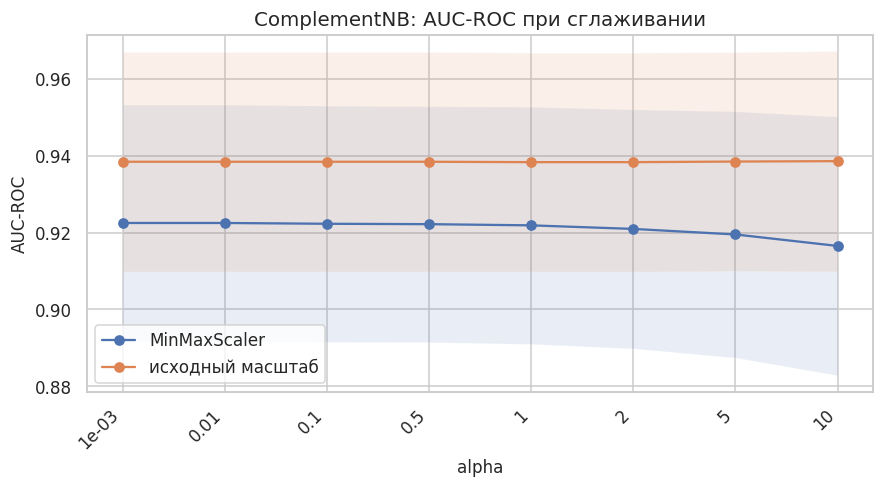


### Вывод по ComplementNB

В финал по правилу из раздела 4 уходит `alpha` = **10**. На кросс-валидации AUC-ROC = 0.9386 ± 0.0287, F1 = 0.8435, Precision = 0.9354, Recall = 0.7706, Accuracy = 0.8945.

Худшая точка этой сетки — `alpha` = 1 (AUC-ROC = 0.9383). Размах AUC-ROC равен 0.0003.

Размах меньше 0.01. В исследованном диапазоне параметр почти не двигает качество: сдвиг сетки сопоставим со стандартным отклонением фолдов в выбранной точке (0.0287) или меньше его. Метод здесь устойчив.

Размах сетки меньше стандартного отклонения по фолдам. Даже если средние чуть отличаются, объявить одну точку победителем по существу нельзя: фолды шумят сильнее, чем сама настройка.

Почти тот же AUC-ROC (отставание от максимума не больше 0.005) дают: 1e-03, 0.01, 0.1, 0.5, 1, 2, 5, 10. Вершина сетки плоская.

В выбранной точке AUC-ROC на обучающей части фолда равен 0.9416, на проверочной — 0.9386, разрыв 0.0030.

Разрыв между обучением и проверкой небольшой, явного переобучения в выбранной точке нет.

База сводной таблицы — MinMax и `alpha=1`, AUC-ROC = 0.9219. Выбрано `исходный масштаб, alpha=10`, прирост +0.0167.

Лучший ComplementNB (AUC-ROC 0.9386) и лучший MultinomialNB (0.9385) расходятся меньше чем на 0.01. При умеренном дисбалансе 63/37 оценка по дополнению класса не даёт отдельного выигрыша: редкому классу и так хватает объектов, чтобы оценить средние.

Как и мультиномиальная модель, ComplementNB требует неотрицательных признаков и не описывает непрерывные измерения теоретически честно. Его место в отчёте — проверить, нужен ли поправочный байесовский вариант под дисбаланс. Ответ дают цифры выше, а не название метода.


In [7]:
rows = []
for scale in (False, True):
    for alpha in alphas:
        metrics = evaluate_cv(make_complement(alpha, scale=scale), X_train, y_train)
        rows.append(
            {
                "scale": scale,
                "group": "MinMaxScaler" if scale else "исходный масштаб",
                "alpha": alpha,
                "param_label": format_param(alpha),
                **metrics,
            }
        )
comp_df = pd.DataFrame(rows)
plot_lines(
    comp_df,
    "group",
    ["MinMaxScaler", "исходный масштаб"],
    "alpha",
    "ComplementNB: AUC-ROC при сглаживании",
)

candidates = []
for scale, sub in comp_df.groupby("scale"):
    candidates.append(select_best(sub.copy()))
selected = select_best(pd.DataFrame(candidates))
use_scale = bool(selected["scale"])
selected_branch = comp_df[comp_df["scale"] == use_scale]
default_row = comp_df[(comp_df["scale"]) & (comp_df["alpha"] == 1.0)].iloc[0]
scale_name = "MinMaxScaler" if use_scale else "исходный масштаб"
params = {"alpha": float(selected["alpha"]), "scale": use_scale}
params_text = f"{scale_name}, alpha={format_param(selected['alpha'])}"
remember(
    "ComplementNB",
    "complement",
    params,
    params_text,
    selected,
    float(default_row["roc_auc"]),
    "MinMaxScaler, alpha=1",
)

multi_best = best_configs["MultinomialNB"]["cv_roc_auc"]
delta_nb = float(selected["roc_auc"] - multi_best)
if abs(delta_nb) < 0.01:
    vs_multi = (
        f"Лучший ComplementNB (AUC-ROC {selected['roc_auc']:.4f}) и лучший MultinomialNB "
        f"({multi_best:.4f}) расходятся меньше чем на 0.01. При умеренном дисбалансе 63/37 "
        "оценка по дополнению класса не даёт отдельного выигрыша: редкому классу и так хватает объектов, чтобы оценить средние."
    )
elif delta_nb > 0:
    vs_multi = (
        f"ComplementNB выше лучшего MultinomialNB на {delta_nb:.4f} "
        f"({selected['roc_auc']:.4f} против {multi_best:.4f}). "
        "Оценка по объектам противоположного класса здесь устойчивее прямой оценки злокачественного класса."
    )
else:
    vs_multi = (
        f"ComplementNB ниже лучшего MultinomialNB на {-delta_nb:.4f} "
        f"({selected['roc_auc']:.4f} против {multi_best:.4f}). "
        "Механизм, придуманный для сильно несбалансированных текстов, на умеренном перекосе медицинских измерений не помогает и слегка портит оценку."
    )

text = f'''
### Вывод по ComplementNB

{interpret_sweep(selected_branch, "alpha", selected)}

База сводной таблицы — MinMax и `alpha=1`, AUC-ROC = {default_row['roc_auc']:.4f}. Выбрано `{params_text}`, прирост {selected['roc_auc'] - default_row['roc_auc']:+.4f}.

{vs_multi}

Как и мультиномиальная модель, ComplementNB требует неотрицательных признаков и не описывает непрерывные измерения теоретически честно. Его место в отчёте — проверить, нужен ли поправочный байесовский вариант под дисбаланс. Ответ дают цифры выше, а не название метода.
'''
display(Markdown(text))

### 5.4. BernoulliNB

Непрерывный признак переводится в 0/1 одним общим порогом. Сетка порогов строится **после** `MinMaxScaler`, иначе число 0.5 для площади и для гладкости означает разное. Пороги: 0, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8. Для каждого порога перебирается `alpha`. Порог 0 оставлен в сетке специально: после MinMax почти все значения строго положительны, и порог 0 превращает их в единицы. Это типичная ошибка «включу BernoulliNB на сырых числах с порогом по умолчанию». Отдельно считается и совсем сырой вариант с порогом 0, без MinMax.

Порог 0.5 после MinMax — середина диапазона от минимума до максимума, а не медиана. У скошенной площади большинство объектов лежит ближе к минимуму, так что порог 0.5 легко оставляет почти весь класс по одну сторону. Поэтому оптимум не обязан оказаться в 0.5.

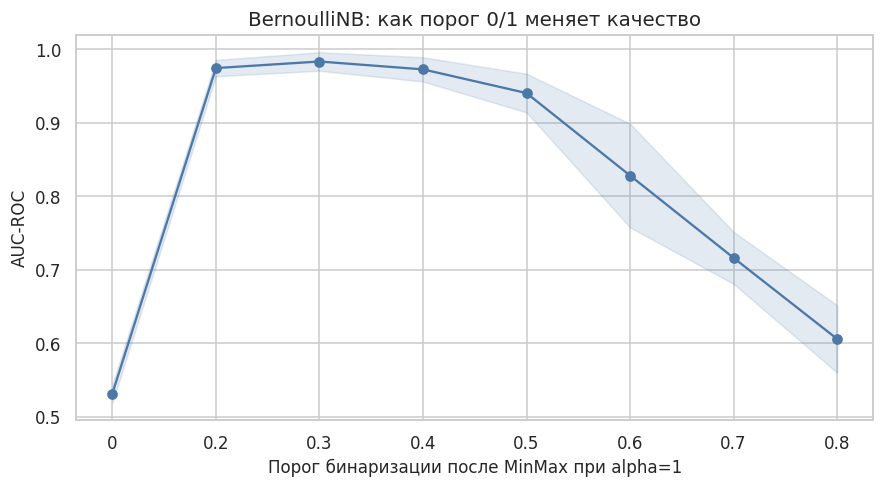

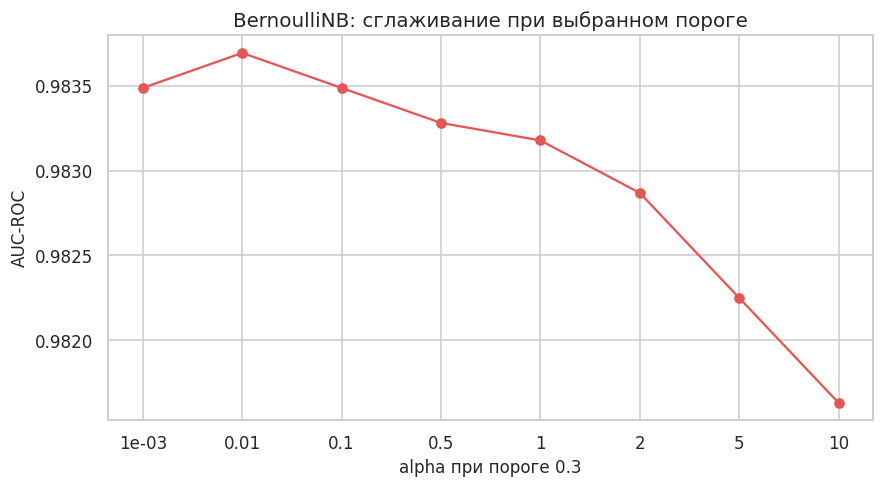


### Вывод по BernoulliNB

Полная сетка — пары «порог, alpha». В финал по правилу из раздела 4 уходит `порог и alpha` = **порог=0.3, alpha=1**. На кросс-валидации AUC-ROC = 0.9832 ± 0.0125, F1 = 0.9256, Precision = 0.9360, Recall = 0.9176, Accuracy = 0.9451.

Худшая точка этой сетки — `порог и alpha` = порог=0, alpha=10 (AUC-ROC = 0.4988). Размах AUC-ROC равен 0.4849.

Размах больше 0.01, значит параметр действительно меняет качество. Значение по умолчанию на этих данных нужно проверять, а не принимать на веру.

Почти тот же AUC-ROC (отставание от максимума не больше 0.005) дают: порог=0.3, alpha=1e-03, порог=0.3, alpha=0.01, порог=0.3, alpha=0.1, порог=0.3, alpha=0.5, порог=0.3, alpha=1, порог=0.3, alpha=2, порог=0.3, alpha=5, порог=0.3, alpha=10. Вершина сетки плоская.

Формальный максимум среднего AUC-ROC находится в точке порог=0.3, alpha=0.01 (0.9837). Выбранная точка уступает ему на 0.0005, но разрыв обучение/проверка у неё меньше (0.0011 против 0.0013). На плоской вершине оставлен более устойчивый вариант.

В выбранной точке AUC-ROC на обучающей части фолда равен 0.9843, на проверочной — 0.9832, разрыв 0.0011.

Разрыв между обучением и проверкой небольшой, явного переобучения в выбранной точке нет.

База сводной таблицы — не библиотечный порог 0, а осмысленный старт после MinMax: порог 0.5 и `alpha=1`, AUC-ROC = 0.9402. Иначе «прирост настройки» смешался бы с исправлением заведомо неудачной бинаризации. Выбрано `MinMaxScaler, порог=0.3, alpha=1`, прирост к этой базе +0.0429.

Порог 0 после MinMax при alpha=1 даёт AUC-ROC 0.5316, выбранный порог — 0.9832, разница 0.4516. Нулевой порог оставляет единицу почти везде, где признак не равен своему минимуму, и объекты перестают отличаться.

Совсем сырой BernoulliNB с порогом 0 и alpha=1, без MinMax, получает AUC-ROC 0.5193. Это заметно хуже подобранного порога на единичном масштабе. Один порог на сырых единицах измерения не имеет общего смысла для площади и для гладкости: площадь всегда выше 0.5, гладкость — почти никогда.

Лучший BernoulliNB (AUC-ROC 0.9832) близок к GaussianNB (0.9870). Порог 0.3 после MinMax — не середина диапазона, а уровень, на котором сохраняется контраст крупного и мелкого ядра. Грубого превышения этого уровня уже почти хватает, потому что классы сильно сдвинуты. Остаток сигнала всё равно сидит в величине отклонения, и GaussianNB его не выбрасывает.

В финал берётся `MinMaxScaler, порог=0.3, alpha=1`. Бернулли здесь — проверка цены бинаризации, а не главный кандидат на лучший метод.


In [8]:
thresholds = [0.0, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
rows = []
for threshold in thresholds:
    for alpha in alphas:
        metrics = evaluate_cv(make_bernoulli(alpha, threshold, scale=True), X_train, y_train)
        rows.append(
            {
                "threshold": threshold,
                "alpha": alpha,
                "param_label": f"порог={format_param(threshold)}, alpha={format_param(alpha)}",
                **metrics,
            }
        )
bern_df = pd.DataFrame(rows)
selected = select_best(bern_df)

alpha_slice = bern_df[bern_df["alpha"] == 1.0].sort_values("threshold")
alpha_slice = alpha_slice.copy()
alpha_slice["param_label"] = alpha_slice["threshold"].map(format_param)
fig, ax = plt.subplots(figsize=(8.2, 4.6))
x_thr = np.arange(len(alpha_slice))
ax.plot(x_thr, alpha_slice["roc_auc"], marker="o", color="#4C78A8", label="AUC-ROC")
ax.fill_between(
    x_thr,
    alpha_slice["roc_auc"] - alpha_slice["roc_auc_std"],
    alpha_slice["roc_auc"] + alpha_slice["roc_auc_std"],
    alpha=0.15,
    color="#4C78A8",
)
ax.set_xticks(x_thr)
ax.set_xticklabels(alpha_slice["param_label"])
ax.set_xlabel("Порог бинаризации после MinMax при alpha=1")
ax.set_ylabel("AUC-ROC")
ax.set_title("BernoulliNB: как порог 0/1 меняет качество")
fig.tight_layout()
plt.show()

thr_best = float(selected["threshold"])
alpha_at_best = bern_df[np.isclose(bern_df["threshold"], thr_best)].sort_values("alpha")
alpha_at_best = alpha_at_best.copy()
alpha_at_best["param_label"] = alpha_at_best["alpha"].map(format_param)
fig, ax = plt.subplots(figsize=(8.2, 4.6))
ax.plot(alpha_at_best["param_label"], alpha_at_best["roc_auc"], marker="o", color="#E45756")
ax.set_xlabel(f"alpha при пороге {format_param(thr_best)}")
ax.set_ylabel("AUC-ROC")
ax.set_title("BernoulliNB: сглаживание при выбранном пороге")
fig.tight_layout()
plt.show()

raw_zero = evaluate_cv(make_bernoulli(alpha=1.0, threshold=0.0, scale=False), X_train, y_train)
minmax_zero = bern_df[np.isclose(bern_df["threshold"], 0.0) & np.isclose(bern_df["alpha"], 1.0)].iloc[0]
default_row = bern_df[np.isclose(bern_df["threshold"], 0.5) & np.isclose(bern_df["alpha"], 1.0)].iloc[0]

params = {"alpha": float(selected["alpha"]), "threshold": thr_best, "scale": True}
params_text = (
    f"MinMaxScaler, порог={format_param(thr_best)}, alpha={format_param(selected['alpha'])}"
)
remember(
    "BernoulliNB",
    "bernoulli",
    params,
    params_text,
    selected,
    float(default_row["roc_auc"]),
    "MinMaxScaler, порог=0.5, alpha=1",
)

zero_gap = float(selected["roc_auc"] - minmax_zero["roc_auc"])
if zero_gap > 0.02:
    zero_comment = (
        f"Порог 0 после MinMax при alpha=1 даёт AUC-ROC {minmax_zero['roc_auc']:.4f}, "
        f"выбранный порог — {selected['roc_auc']:.4f}, разница {zero_gap:.4f}. "
        "Нулевой порог оставляет единицу почти везде, где признак не равен своему минимуму, и объекты перестают отличаться."
    )
elif zero_gap > 0:
    zero_comment = (
        f"Порог 0 после MinMax лишь немного хуже выбранного: {minmax_zero['roc_auc']:.4f} против {selected['roc_auc']:.4f}. "
        "Часть признаков полезна уже фактом «не минимальное значение», но лучший порог всё же сохраняет больше контраста."
    )
else:
    zero_comment = (
        f"Порог 0 после MinMax не хуже выбранной точки ({minmax_zero['roc_auc']:.4f}). "
        "Для этих признаков важен сам факт отклонения от минимума. Это редкий случай, и он виден только потому, что порог 0 оставлен в сетке."
    )

raw_comment = (
    f"Совсем сырой BernoulliNB с порогом 0 и alpha=1, без MinMax, получает AUC-ROC {raw_zero['roc_auc']:.4f}. "
)
if raw_zero["roc_auc"] + 0.05 < selected["roc_auc"]:
    raw_comment += (
        "Это заметно хуже подобранного порога на единичном масштабе. Один порог на сырых единицах измерения "
        "не имеет общего смысла для площади и для гладкости: площадь всегда выше 0.5, гладкость — почти никогда."
    )
else:
    raw_comment += (
        "Даже грубый сырой порог сохраняет часть сигнала. Его дают признаки, которые хотя бы иногда равны нулю, "
        "например вогнутость. Остальные координаты при пороге 0 всё равно почти константы."
    )

gauss_auc = best_configs["GaussianNB"]["cv_roc_auc"]
bin_gap = gauss_auc - float(selected["roc_auc"])
if bin_gap > 0.02:
    bin_comment = (
        f"Даже лучшая бинаризация отстаёт от GaussianNB на {bin_gap:.4f} по CV AUC-ROC "
        f"({selected['roc_auc']:.4f} против {gauss_auc:.4f}). "
        "Порог выбрасывает величину отклонения. Для ядра важно не только «большое / маленькое», но и насколько оно большое."
    )
else:
    bin_comment = (
        f"Лучший BernoulliNB (AUC-ROC {selected['roc_auc']:.4f}) близок к GaussianNB ({gauss_auc:.4f}). "
        f"Порог {format_param(thr_best)} после MinMax — не середина диапазона, а уровень, "
        "на котором сохраняется контраст крупного и мелкого ядра. Грубого превышения этого уровня уже почти хватает, "
        "потому что классы сильно сдвинуты. Остаток сигнала всё равно сидит в величине отклонения, и GaussianNB его не выбрасывает."
    )

text = f'''
### Вывод по BernoulliNB

Полная сетка — пары «порог, alpha». {interpret_sweep(bern_df, "порог и alpha", selected)}

База сводной таблицы — не библиотечный порог 0, а осмысленный старт после MinMax: порог 0.5 и `alpha=1`, AUC-ROC = {default_row['roc_auc']:.4f}. Иначе «прирост настройки» смешался бы с исправлением заведомо неудачной бинаризации. Выбрано `{params_text}`, прирост к этой базе {selected['roc_auc'] - default_row['roc_auc']:+.4f}.

{zero_comment}

{raw_comment}

{bin_comment}

В финал берётся `{params_text}`. Бернулли здесь — проверка цены бинаризации, а не главный кандидат на лучший метод.
'''
display(Markdown(text))

### 5.5. Дерево решений

Сначала на графике показан самый наглядный срез: критерий Джини, минимум 1 объект в листе, глубина от 1 до 12 и вариант без ограничения. На этом срезе видны недообучение короткого дерева и расхождение обучения с проверкой у глубокого. Финальные параметры выбираются не по срезу, а по полной сетке: глубина, `min_samples_leaf` из {1, 5, 10, 20} и критерий Джини или энтропия. Масштабирование не используется.

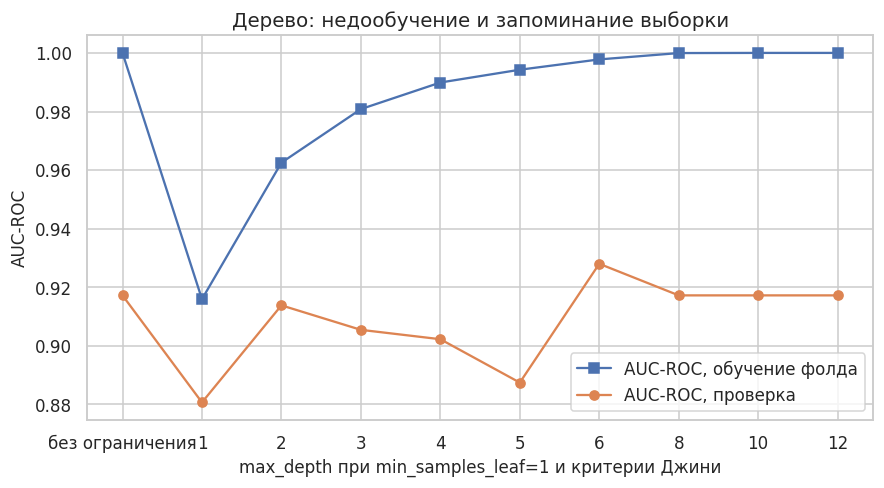


### Вывод по дереву решений

График — срез, а не вся сетка. На срезе дерево глубины 1 получает проверочный AUC-ROC 0.8807: одного вопроса недостаточно, это недообучение. Дерево без ограничения глубины при листе из одного объекта доходит до обучающего AUC-ROC 1.0000 при проверочном 0.9172. Разрыв 0.0828. Модель запоминает конкретные пороги обучающего фолда.

Полная сетка включает ещё минимум объектов в листе и критерий. В финал по правилу из раздела 4 уходит `глубина, лист и критерий` = **depth=5, leaf=20, gini**. На кросс-валидации AUC-ROC = 0.9594 ± 0.0211, F1 = 0.8881, Precision = 0.8955, Recall = 0.8824, Accuracy = 0.9165.

Худшая точка этой сетки — `глубина, лист и критерий` = depth=1, leaf=1, gini (AUC-ROC = 0.8807). Размах AUC-ROC равен 0.0787.

Размах больше 0.01, значит параметр действительно меняет качество. Значение по умолчанию на этих данных нужно проверять, а не принимать на веру.

Почти тот же AUC-ROC (отставание от максимума не больше 0.005) дают: depth=4, leaf=20, gini, depth=4, leaf=20, entropy, depth=5, leaf=5, gini, depth=5, leaf=10, gini, depth=5, leaf=20, gini, depth=5, leaf=20, entropy, depth=6, leaf=5, gini, depth=6, leaf=10, gini и ещё 14. Вершина сетки плоская.

В выбранной точке AUC-ROC на обучающей части фолда равен 0.9884, на проверочной — 0.9594, разрыв 0.0290.

Разрыв между обучением и проверкой небольшой, явного переобучения в выбранной точке нет.

Библиотечная база — дерево без ограничения глубины, `min_samples_leaf=1`, Джини. Её CV AUC-ROC = 0.9172. Выбрано `depth=5, leaf=20, gini`, прирост +0.0422. Положительный прирост здесь часто означает не «более умное дерево», а отказ от переобученной глубины: проверочный AUC растёт, когда листьям запрещают быть слишком мелкими.

Лучший Джини даёт AUC-ROC 0.9594, лучшая энтропия — 0.9530. Разница меньше 0.01. Оба критерия измеряют одну и ту же неоднородность узла немного разными формулами, а классы здесь разделяются грубыми порогами по размеру. Смена критерия почти ничего не решает.

Отрыв выбранного дерева от пня глубины 1 составляет 0.0787 по AUC-ROC. Глубина нужна, но небольшая. Масштаб признаков на решение не влияет, поэтому конвейер без `StandardScaler` — осознанный, а не пропущенный шаг. В финал идёт `depth=5, leaf=20, gini`.


In [9]:
depths = [1, 2, 3, 4, 5, 6, 8, 10, 12, None]
leaves = [1, 5, 10, 20]
criteria = ["gini", "entropy"]
rows = []
for depth in depths:
    for leaf in leaves:
        for criterion in criteria:
            metrics = evaluate_cv(
                make_tree(depth, leaf, criterion),
                X_train,
                y_train,
            )
            rows.append(
                {
                    "max_depth": depth if depth is not None else -1,
                    "min_samples_leaf": leaf,
                    "criterion": criterion,
                    "param_label": (
                        f"depth={format_param(depth)}, leaf={leaf}, {criterion}"
                    ),
                    **metrics,
                }
            )
tree_df = pd.DataFrame(rows)
selected = select_best(tree_df)

slice_df = tree_df[
    (tree_df["min_samples_leaf"] == 1) & (tree_df["criterion"] == "gini")
].sort_values("max_depth")
fig, ax = plt.subplots(figsize=(8.2, 4.6))
x = np.arange(len(slice_df))
ax.plot(x, slice_df["roc_auc_train"], marker="s", label="AUC-ROC, обучение фолда")
ax.plot(x, slice_df["roc_auc"], marker="o", label="AUC-ROC, проверка")
ax.set_xticks(x)
ax.set_xticklabels(slice_df["max_depth"].map(lambda v: "без ограничения" if v < 0 else str(int(v))))
ax.set_xlabel("max_depth при min_samples_leaf=1 и критерии Джини")
ax.set_ylabel("AUC-ROC")
ax.set_title("Дерево: недообучение и запоминание выборки")
ax.legend()
fig.tight_layout()
plt.show()

default_row = tree_df[
    (tree_df["max_depth"] < 0)
    & (tree_df["min_samples_leaf"] == 1)
    & (tree_df["criterion"] == "gini")
].iloc[0]
unlimited = slice_df[slice_df["max_depth"] < 0].iloc[0]
shallow = slice_df[slice_df["max_depth"] == 1].iloc[0]

depth_value = None if int(selected["max_depth"]) < 0 else int(selected["max_depth"])
params = {
    "max_depth": depth_value,
    "min_samples_leaf": int(selected["min_samples_leaf"]),
    "criterion": selected["criterion"],
}
params_text = selected["param_label"]
remember(
    "Дерево",
    "tree",
    params,
    params_text,
    selected,
    float(default_row["roc_auc"]),
    "depth=None, leaf=1, gini",
)

overfit_gap = float(unlimited["roc_auc_train"] - unlimited["roc_auc"])
shallow_gap = float(selected["roc_auc"] - shallow["roc_auc"])
gini_best = select_best(tree_df[tree_df["criterion"] == "gini"].copy())
entropy_best = select_best(tree_df[tree_df["criterion"] == "entropy"].copy())
crit_delta = abs(float(gini_best["roc_auc"] - entropy_best["roc_auc"]))
if crit_delta < 0.01:
    crit_comment = (
        f"Лучший Джини даёт AUC-ROC {gini_best['roc_auc']:.4f}, лучшая энтропия — {entropy_best['roc_auc']:.4f}. "
        "Разница меньше 0.01. Оба критерия измеряют одну и ту же неоднородность узла немного разными формулами, "
        "а классы здесь разделяются грубыми порогами по размеру. Смена критерия почти ничего не решает."
    )
else:
    winner_name = "энтропия" if entropy_best["roc_auc"] > gini_best["roc_auc"] else "Джини"
    crit_comment = (
        f"Критерии расходятся больше чем на 0.01: Джини {gini_best['roc_auc']:.4f}, "
        f"энтропия {entropy_best['roc_auc']:.4f}. В финал уходит {winner_name}, "
        "потому что на этой сетке она честнее отделяет смешанные узлы."
    )

text = f'''
### Вывод по дереву решений

График — срез, а не вся сетка. На срезе дерево глубины 1 получает проверочный AUC-ROC {shallow['roc_auc']:.4f}: одного вопроса недостаточно, это недообучение. Дерево без ограничения глубины при листе из одного объекта доходит до обучающего AUC-ROC {unlimited['roc_auc_train']:.4f} при проверочном {unlimited['roc_auc']:.4f}. Разрыв {overfit_gap:.4f}. Модель запоминает конкретные пороги обучающего фолда.

Полная сетка включает ещё минимум объектов в листе и критерий. {interpret_sweep(tree_df, "глубина, лист и критерий", selected)}

Библиотечная база — дерево без ограничения глубины, `min_samples_leaf=1`, Джини. Её CV AUC-ROC = {default_row['roc_auc']:.4f}. Выбрано `{params_text}`, прирост {selected['roc_auc'] - default_row['roc_auc']:+.4f}. Положительный прирост здесь часто означает не «более умное дерево», а отказ от переобученной глубины: проверочный AUC растёт, когда листьям запрещают быть слишком мелкими.

{crit_comment}

Отрыв выбранного дерева от пня глубины 1 составляет {shallow_gap:.4f} по AUC-ROC. Глубина нужна, но небольшая. Масштаб признаков на решение не влияет, поэтому конвейер без `StandardScaler` — осознанный, а не пропущенный шаг. В финал идёт `{params_text}`.
'''
display(Markdown(text))

### 5.6. LDA

Сравниваются солвер `svd` без сжатия и солвер `lsqr` со сжатием 0, 0.1, 0.25, 0.5, 0.75, 1 и `'auto'`. Основная сетка считается после `StandardScaler`, потому что сжатие к диагонали имеет смысл только на признаках одной дисперсии. Отдельно `svd` прогоняется на сырых признаках: без регуляризации линейный дискриминант должен быть почти безразличен к масштабу, и это проверка, что конвейер не ломает модель.

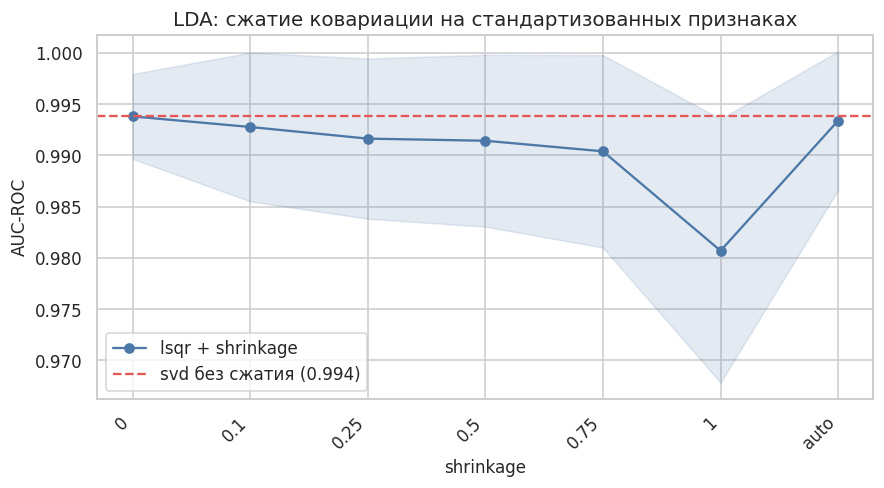


### Вывод по LDA

В финал по правилу из раздела 4 уходит `солвер и shrinkage` = **lsqr, shrinkage=0.5**. На кросс-валидации AUC-ROC = 0.9914 ± 0.0084, F1 = 0.9338, Precision = 0.9941, Recall = 0.8824, Accuracy = 0.9538.

Худшая точка этой сетки — `солвер и shrinkage` = lsqr, shrinkage=1 (AUC-ROC = 0.9807). Размах AUC-ROC равен 0.0131.

Размах больше 0.01, значит параметр действительно меняет качество. Значение по умолчанию на этих данных нужно проверять, а не принимать на веру.

Почти тот же AUC-ROC (отставание от максимума не больше 0.005) дают: lsqr, shrinkage=0, lsqr, shrinkage=0.1, lsqr, shrinkage=0.25, lsqr, shrinkage=0.5, lsqr, shrinkage=0.75, lsqr, shrinkage=auto, svd, без shrinkage. Вершина сетки плоская.

Формальный максимум среднего AUC-ROC находится в точке lsqr, shrinkage=0 (0.9938). Выбранная точка уступает ему на 0.0024, но разрыв обучение/проверка у неё меньше (0.0013 против 0.0035). На плоской вершине оставлен более устойчивый вариант.

В выбранной точке AUC-ROC на обучающей части фолда равен 0.9928, на проверочной — 0.9914, разрыв 0.0013.

Разрыв между обучением и проверкой небольшой, явного переобучения в выбранной точке нет.

База сводной таблицы — `svd` без сжатия на стандартизованных признаках, AUC-ROC = 0.9938. Выбрано `lsqr, shrinkage=0.5, StandardScaler`, прирост -0.0024. `lsqr` при shrinkage=0 даёт 0.9938: другой солвер при том же отсутствии сжатия не обязан совпасть с SVD до третьего знака, потому что по-разному обходит почти зависимые столбцы радиуса, периметра и площади.

SVD без сжатия почти не замечает стандартизацию: AUC-ROC 0.9938 на масштабированных признаках и 0.9938 на сырых, разница 0.0000. Так и должно быть: без регуляризации дискриминант смотрит на расстояние Махаланобиса и сам учитывает масштаб.

Полное сжатие (shrinkage=1, AUC-ROC 0.9807) хуже выбранной точки. Обнулить все корреляции нельзя: совместный размер ядра несёт согласованный сигнал, и диагональная модель его дробит.

Прирост выбранной точки к SVD равен -0.0024: сжатие не поднимает средний AUC. Точка shrinkage=0.5 осталась в финале, потому что на плоской вершине у неё меньше разрыв обучения и проверки, а не потому что она точнее. Полное обнуление корреляций уже вредит (shrinkage=1, AUC-ROC 0.9807). Умеренная зависимость радиуса, периметра и площади LDA не ломает, а чрезмерное сжатие выбрасывает согласованный размерный сигнал.


In [10]:
shrink_values = [0.0, 0.1, 0.25, 0.5, 0.75, 1.0, "auto"]
rows = []
for shrinkage in shrink_values:
    metrics = evaluate_cv(make_lda("lsqr", shrinkage, scale=True), X_train, y_train)
    rows.append(
        {
            "solver": "lsqr",
            "shrinkage": shrinkage if not isinstance(shrinkage, float) else float(shrinkage),
            "param_label": f"lsqr, shrinkage={format_param(shrinkage)}",
            **metrics,
        }
    )
svd_scaled = evaluate_cv(make_lda("svd", None, scale=True), X_train, y_train)
svd_raw = evaluate_cv(make_lda("svd", None, scale=False), X_train, y_train)
rows.append(
    {
        "solver": "svd",
        "shrinkage": None,
        "param_label": "svd, без shrinkage",
        **svd_scaled,
    }
)
lda_df = pd.DataFrame(rows)
selected = select_best(lda_df)

plot_df = lda_df[lda_df["solver"] == "lsqr"].copy()
fig, ax = plt.subplots(figsize=(8.2, 4.6))
x = np.arange(len(plot_df))
ax.plot(x, plot_df["roc_auc"], marker="o", color="#4C78A8", label="lsqr + shrinkage")
ax.fill_between(
    x,
    plot_df["roc_auc"] - plot_df["roc_auc_std"],
    plot_df["roc_auc"] + plot_df["roc_auc_std"],
    alpha=0.15,
    color="#4C78A8",
)
ax.axhline(svd_scaled["roc_auc"], color="#E45756", linestyle="--", label=f"svd без сжатия ({svd_scaled['roc_auc']:.3f})")
ax.set_xticks(x)
ax.set_xticklabels([format_param(v) for v in plot_df["shrinkage"]], rotation=45, ha="right")
ax.set_xlabel("shrinkage")
ax.set_ylabel("AUC-ROC")
ax.set_title("LDA: сжатие ковариации на стандартизованных признаках")
ax.legend()
fig.tight_layout()
plt.show()

if selected["solver"] == "svd":
    params = {"solver": "svd", "shrinkage": None, "scale": True}
else:
    shrink_param = selected["shrinkage"]
    if isinstance(shrink_param, str):
        shrink_store = "auto"
    else:
        shrink_store = float(shrink_param)
    params = {"solver": "lsqr", "shrinkage": shrink_store, "scale": True}
params_text = selected["param_label"] + ", StandardScaler"
remember(
    "LDA",
    "lda",
    params,
    params_text,
    selected,
    float(svd_scaled["roc_auc"]),
    "svd, без shrinkage, StandardScaler",
)

svd_scale_delta = abs(svd_scaled["roc_auc"] - svd_raw["roc_auc"])
if svd_scale_delta < 0.005:
    scale_comment = (
        f"SVD без сжатия почти не замечает стандартизацию: AUC-ROC {svd_scaled['roc_auc']:.4f} на масштабированных признаках "
        f"и {svd_raw['roc_auc']:.4f} на сырых, разница {svd_scale_delta:.4f}. "
        "Так и должно быть: без регуляризации дискриминант смотрит на расстояние Махаланобиса и сам учитывает масштаб."
    )
else:
    scale_comment = (
        f"SVD на сырых данных даёт AUC-ROC {svd_raw['roc_auc']:.4f}, на стандартизованных — {svd_scaled['roc_auc']:.4f}. "
        "Расхождение больше 0.005 и связано с численной устойчивостью почти вырожденной ковариации, а не с содержательной сменой границы."
    )

shrink0 = lda_df[lda_df["param_label"] == "lsqr, shrinkage=0"].iloc[0]
shrink1 = lda_df[lda_df["param_label"] == "lsqr, shrinkage=1"].iloc[0]
if shrink1["roc_auc"] + 0.01 < selected["roc_auc"]:
    shrink_comment = (
        f"Полное сжатие (shrinkage=1, AUC-ROC {shrink1['roc_auc']:.4f}) хуже выбранной точки. "
        "Обнулить все корреляции нельзя: совместный размер ядра несёт согласованный сигнал, и диагональная модель его дробит."
    )
else:
    shrink_comment = (
        f"Даже shrinkage=1 держит AUC-ROC {shrink1['roc_auc']:.4f}, рядом с выбранной точкой {selected['roc_auc']:.4f}. "
        "После стандартизации одних дисперсий уже почти хватает. Корреляции размера избыточны для линейного разделения, хотя геометрически они огромны."
    )

lda_gain = float(selected["roc_auc"] - svd_scaled["roc_auc"])
if lda_gain < -0.002:
    shrink_story = (
        f"Прирост выбранной точки к SVD равен {lda_gain:+.4f}: сжатие не поднимает средний AUC. "
        "Точка shrinkage=0.5 осталась в финале, потому что на плоской вершине у неё меньше разрыв обучения и проверки, а не потому что она точнее. "
        f"Полное обнуление корреляций уже вредит (shrinkage=1, AUC-ROC {shrink1['roc_auc']:.4f}). "
        "Умеренная зависимость радиуса, периметра и площади LDA не ломает, а чрезмерное сжатие выбрасывает согласованный размерный сигнал."
    )
elif lda_gain < 0.005:
    shrink_story = (
        f"Прирост к SVD равен {lda_gain:+.4f}. Сжатие почти не меняет качество: классы и так линейно разделимы, "
        "а регуляризация лишь слегка стабилизирует оценку ковариации."
    )
else:
    shrink_story = (
        f"Прирост к SVD равен {lda_gain:+.4f}. Без сжатия ковариация переоценивает шум в зависимых размерных признаках, "
        "и shrinkage это исправляет."
    )

text = f'''
### Вывод по LDA

{interpret_sweep(lda_df, "солвер и shrinkage", selected)}

База сводной таблицы — `svd` без сжатия на стандартизованных признаках, AUC-ROC = {svd_scaled['roc_auc']:.4f}. Выбрано `{params_text}`, прирост {selected['roc_auc'] - svd_scaled['roc_auc']:+.4f}. `lsqr` при shrinkage=0 даёт {shrink0['roc_auc']:.4f}: другой солвер при том же отсутствии сжатия не обязан совпасть с SVD до третьего знака, потому что по-разному обходит почти зависимые столбцы радиуса, периметра и площади.

{scale_comment}

{shrink_comment}

{shrink_story}
'''
display(Markdown(text))

### 5.7. SVM

Сетка после `StandardScaler`:

- линейное ядро, `C` из {0.01, 0.1, 1, 10, 100}, веса классов обычные и `balanced`;
- ядро RBF, те же `C`, `gamma` из {0.01, 0.1, 1, `scale`}, те же два режима весов.

`gamma='scale'` в scikit-learn равен \(1 / (n_{\text{признаков}} \cdot \mathrm{Var})\). После стандартизации это около \(1/30\). Малый `C` недообучает, очень большая `gamma` делает ядро локальным. Отдельно один раз считается RBF с `C=1` и `gamma='scale'` **без** стандартизации, чтобы плата за разный масштаб была числом, а не общим советом.

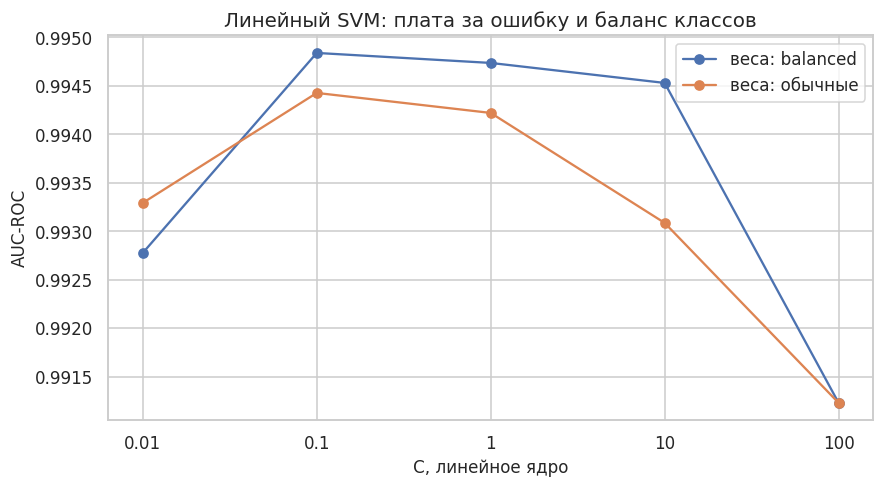

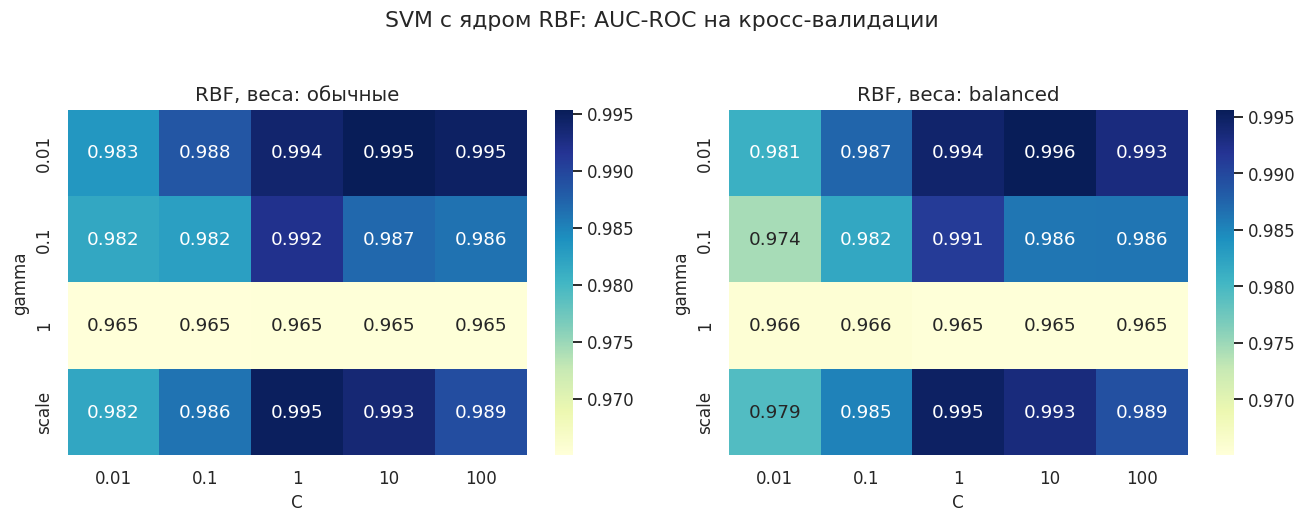


### Вывод по SVM

В финал по правилу из раздела 4 уходит `ядро, C, gamma и веса` = **linear, C=0.01, веса=обычные**. На кросс-валидации AUC-ROC = 0.9933 ± 0.0072, F1 = 0.9472, Precision = 0.9941, Recall = 0.9059, Accuracy = 0.9626.

Худшая точка этой сетки — `ядро, C, gamma и веса` = rbf, C=0.1, gamma=1, веса=обычные (AUC-ROC = 0.9650). Размах AUC-ROC равен 0.0307.

Размах больше 0.01, значит параметр действительно меняет качество. Значение по умолчанию на этих данных нужно проверять, а не принимать на веру.

Почти тот же AUC-ROC (отставание от максимума не больше 0.005) дают: linear, C=0.01, веса=обычные, linear, C=0.01, веса=balanced, linear, C=0.1, веса=обычные, linear, C=0.1, веса=balanced, linear, C=1, веса=обычные, rbf, C=1, gamma=0.01, веса=обычные, rbf, C=1, gamma=0.1, веса=обычные, rbf, C=1, gamma=scale, веса=обычные и ещё 14. Вершина сетки плоская.

Формальный максимум среднего AUC-ROC находится в точке rbf, C=10, gamma=0.01, веса=balanced (0.9957). Выбранная точка уступает ему на 0.0024, но разрыв обучение/проверка у неё меньше (0.0010 против 0.0024). На плоской вершине оставлен более устойчивый вариант.

В выбранной точке AUC-ROC на обучающей части фолда равен 0.9943, на проверочной — 0.9933, разрыв 0.0010.

Разрыв между обучением и проверкой небольшой, явного переобучения в выбранной точке нет.

База сводной таблицы — документация scikit-learn плюс обязательное масштабирование: RBF, `C=1`, `gamma=scale`, обычные веса. CV AUC-ROC = 0.9949. Выбрано `linear, C=0.01, веса=обычные, StandardScaler`, прирост -0.0017.

Лучшее линейное ядро (AUC-ROC 0.9933, linear, C=0.01, веса=обычные) и лучший RBF (0.9944, rbf, C=1, gamma=0.01, веса=balanced) расходятся меньше чем на 0.01. После стандартизации классы почти линейно разделимы. Гибкость RBF не открывает новой структуры, она в лучшем случае повторяет гиперплоскость.

Тот же RBF с C=1 и gamma=scale без стандартизации получает AUC-ROC 0.9709 против 0.9949 со StandardScaler. Потеря 0.0240. Скалярное произведение без масштаба почти целиком состоит из площади и периметра.

Худшие клетки сетки — это не малый `C`, а слишком узкое ядро: при `gamma=1` каждый опорный вектор влияет только на ближайшие точки, и AUC падает. Малый `C` расширяет полосу. На этих данных классы разделены с запасом, поэтому даже `C=0.01` остаётся среди лучших линейных точек, а не проваливается в недообучение. `class_weight='balanced'` имеет смысл читать по Recall: баланс штрафа сдвигает порог в пользу злокачественного класса, тогда как AUC может почти не измениться. В финале у выбранной модели включён `probability=True`, чтобы ROC и порог 0.5 жили на одной вероятностной шкале. Сама сетка калибровку Платта не подбирала.


In [11]:
C_values = [0.01, 0.1, 1.0, 10.0, 100.0]
gammas = [0.01, 0.1, 1.0, "scale"]
rows = []
for C in C_values:
    for class_weight in (None, "balanced"):
        metrics = evaluate_cv(
            make_svm(C=C, kernel="linear", class_weight=class_weight, scale=True),
            X_train,
            y_train,
        )
        rows.append(
            {
                "kernel": "linear",
                "C": C,
                "gamma": "—",
                "class_weight": "balanced" if class_weight == "balanced" else "обычные",
                "param_label": f"linear, C={format_param(C)}, веса={'balanced' if class_weight == 'balanced' else 'обычные'}",
                **metrics,
            }
        )
        for gamma in gammas:
            metrics = evaluate_cv(
                make_svm(C=C, kernel="rbf", gamma=gamma, class_weight=class_weight, scale=True),
                X_train,
                y_train,
            )
            rows.append(
                {
                    "kernel": "rbf",
                    "C": C,
                    "gamma": gamma,
                    "class_weight": "balanced" if class_weight == "balanced" else "обычные",
                    "param_label": (
                        f"rbf, C={format_param(C)}, gamma={format_param(gamma)}, "
                        f"веса={'balanced' if class_weight == 'balanced' else 'обычные'}"
                    ),
                    **metrics,
                }
            )
svm_df = pd.DataFrame(rows)
selected = select_best(svm_df)

linear = svm_df[svm_df["kernel"] == "linear"]
fig, ax = plt.subplots(figsize=(8.2, 4.6))
for weight, sub in linear.groupby("class_weight"):
    sub = sub.sort_values("C")
    ax.plot(sub["C"].map(format_param), sub["roc_auc"], marker="o", label=f"веса: {weight}")
ax.set_xlabel("C, линейное ядро")
ax.set_ylabel("AUC-ROC")
ax.set_title("Линейный SVM: плата за ошибку и баланс классов")
ax.legend()
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.6))
for ax, weight in zip(axes, ["обычные", "balanced"]):
    sub = svm_df[(svm_df["kernel"] == "rbf") & (svm_df["class_weight"] == weight)]
    pivot = sub.pivot(index="gamma", columns="C", values="roc_auc")
    pivot.index = [format_param(v) for v in pivot.index]
    pivot.columns = [format_param(v) for v in pivot.columns]
    sns.heatmap(pivot, annot=True, fmt=".3f", cmap="YlGnBu", ax=ax, vmin=float(svm_df["roc_auc"].min()))
    ax.set_title(f"RBF, веса: {weight}")
    ax.set_xlabel("C")
    ax.set_ylabel("gamma")
fig.suptitle("SVM с ядром RBF: AUC-ROC на кросс-валидации", y=1.03)
fig.tight_layout()
plt.show()

raw_svm = evaluate_cv(
    make_svm(C=1.0, kernel="rbf", gamma="scale", class_weight=None, scale=False),
    X_train,
    y_train,
)
default_row = svm_df[
    (svm_df["kernel"] == "rbf")
    & np.isclose(svm_df["C"], 1.0)
    & (svm_df["gamma"] == "scale")
    & (svm_df["class_weight"] == "обычные")
].iloc[0]

weight_value = None if selected["class_weight"] == "обычные" else "balanced"
gamma_value = selected["gamma"]
if gamma_value != "—" and gamma_value != "scale":
    gamma_value = float(gamma_value)
params = {
    "C": float(selected["C"]),
    "kernel": selected["kernel"],
    "gamma": "scale" if selected["kernel"] == "linear" else gamma_value,
    "class_weight": weight_value,
    "scale": True,
}
params_text = selected["param_label"] + ", StandardScaler"
remember(
    "SVM",
    "svm",
    params,
    params_text,
    selected,
    float(default_row["roc_auc"]),
    "StandardScaler, rbf, C=1, gamma=scale, обычные веса",
)

best_linear = select_best(linear.copy())
best_rbf = select_best(svm_df[svm_df["kernel"] == "rbf"].copy())
kernel_delta = float(best_rbf["roc_auc"] - best_linear["roc_auc"])
if abs(kernel_delta) < 0.01:
    kernel_comment = (
        f"Лучшее линейное ядро (AUC-ROC {best_linear['roc_auc']:.4f}, {best_linear['param_label']}) "
        f"и лучший RBF ({best_rbf['roc_auc']:.4f}, {best_rbf['param_label']}) расходятся меньше чем на 0.01. "
        "После стандартизации классы почти линейно разделимы. Гибкость RBF не открывает новой структуры, она в лучшем случае повторяет гиперплоскость."
    )
elif kernel_delta > 0:
    kernel_comment = (
        f"RBF лучше линейного ядра на {kernel_delta:.4f} "
        f"({best_rbf['roc_auc']:.4f} против {best_linear['roc_auc']:.4f}). "
        "Граница не укладывается в одну гиперплоскость: локальные гауссовы функции подбирают изгиб там, где размер и форма контура взаимодействуют."
    )
else:
    kernel_comment = (
        f"Линейное ядро лучше RBF на {-kernel_delta:.4f} "
        f"({best_linear['roc_auc']:.4f} против {best_rbf['roc_auc']:.4f}). "
        "Дополнительная ёмкость RBF на 455 объектах начинает подгоняться под фолды, а простая гиперплоскость обобщает лучше."
    )

raw_gap = float(default_row["roc_auc"] - raw_svm["roc_auc"])
if raw_gap > 0.01:
    raw_comment = (
        f"Тот же RBF с C=1 и gamma=scale без стандартизации получает AUC-ROC {raw_svm['roc_auc']:.4f} "
        f"против {default_row['roc_auc']:.4f} со StandardScaler. Потеря {raw_gap:.4f}. "
        "Скалярное произведение без масштаба почти целиком состоит из площади и периметра."
    )
else:
    raw_comment = (
        f"Без стандартизации базовый RBF получает AUC-ROC {raw_svm['roc_auc']:.4f}, "
        f"со стандартизацией — {default_row['roc_auc']:.4f}. "
        "На этом конкретном ядре и C масштаб почти не меняет ранжирование: доминирующий размерный сигнал и так совпадает с классом. "
        "Стандартизация всё равно оставлена, потому что gamma и C на сырых данных значат другое и сетка перестала бы быть сопоставимой."
    )

text = f'''
### Вывод по SVM

{interpret_sweep(svm_df, "ядро, C, gamma и веса", selected)}

База сводной таблицы — документация scikit-learn плюс обязательное масштабирование: RBF, `C=1`, `gamma=scale`, обычные веса. CV AUC-ROC = {default_row['roc_auc']:.4f}. Выбрано `{params_text}`, прирост {selected['roc_auc'] - default_row['roc_auc']:+.4f}.

{kernel_comment}

{raw_comment}

Худшие клетки сетки — это не малый `C`, а слишком узкое ядро: при `gamma=1` каждый опорный вектор влияет только на ближайшие точки, и AUC падает. Малый `C` расширяет полосу. На этих данных классы разделены с запасом, поэтому даже `C=0.01` остаётся среди лучших линейных точек, а не проваливается в недообучение. `class_weight='balanced'` имеет смысл читать по Recall: баланс штрафа сдвигает порог в пользу злокачественного класса, тогда как AUC может почти не измениться. В финале у выбранной модели включён `probability=True`, чтобы ROC и порог 0.5 жили на одной вероятностной шкале. Сама сетка калибровку Платта не подбирала.
'''
display(Markdown(text))

### 5.8. k ближайших соседей

Число соседей меняется от 1 до 25. Для каждого k сравниваются веса `uniform` и `distance` и метрики `euclidean` и `manhattan`. Все эти ветки идут после `StandardScaler`. На графике две панели: AUC-ROC показывает качество ранжирования, Recall — что происходит с порогом большинства. Дополнительно считается k = 5, `uniform`, евклидова метрика без масштабирования.

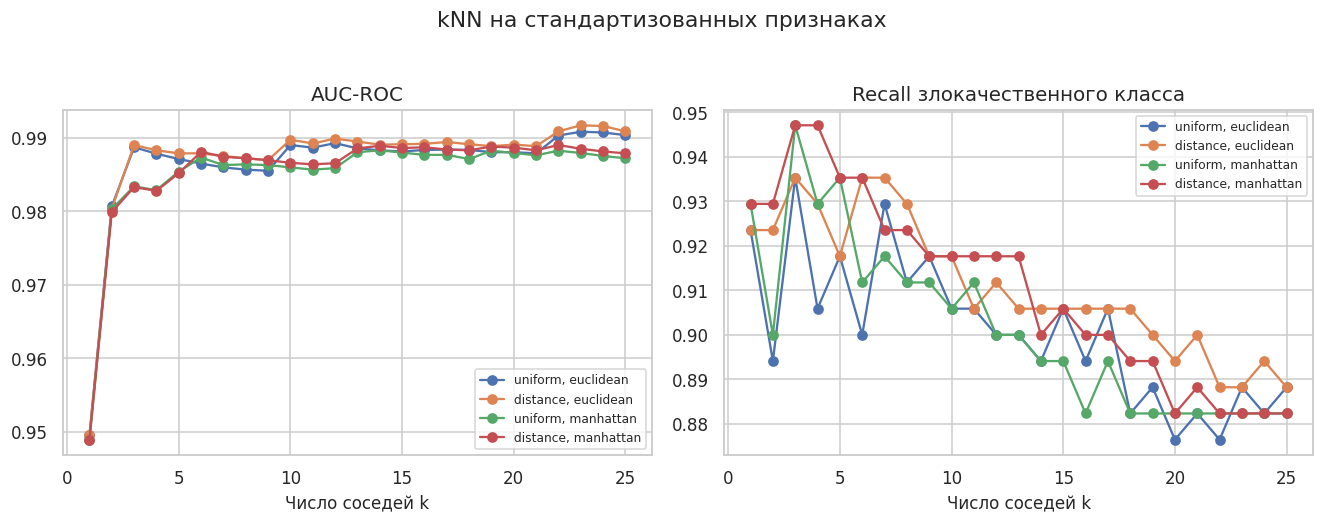


### Вывод по kNN

В финал по правилу из раздела 4 уходит `k, веса и метрика` = **k=24, uniform, euclidean**. На кросс-валидации AUC-ROC = 0.9907 ± 0.0089, F1 = 0.9333, Precision = 0.9933, Recall = 0.8824, Accuracy = 0.9538.

Худшая точка этой сетки — `k, веса и метрика` = k=1, uniform, manhattan (AUC-ROC = 0.9489). Размах AUC-ROC равен 0.0428.

Размах больше 0.01, значит параметр действительно меняет качество. Значение по умолчанию на этих данных нужно проверять, а не принимать на веру.

Почти тот же AUC-ROC (отставание от максимума не больше 0.005) дают: k=3, uniform, euclidean, k=3, distance, euclidean, k=4, uniform, euclidean, k=4, distance, euclidean, k=5, uniform, euclidean, k=5, distance, euclidean, k=6, uniform, manhattan, k=6, distance, euclidean и ещё 65. Вершина сетки плоская.

Формальный максимум среднего AUC-ROC находится в точке k=23, distance, euclidean (0.9917). Выбранная точка уступает ему на 0.0010, но разрыв обучение/проверка у неё меньше (0.0029 против 0.0083). На плоской вершине оставлен более устойчивый вариант.

В выбранной точке AUC-ROC на обучающей части фолда равен 0.9936, на проверочной — 0.9907, разрыв 0.0029.

Разрыв между обучением и проверкой небольшой, явного переобучения в выбранной точке нет.

База сводной таблицы — частый учебный старт: k=5, равные веса, евклидова метрика, StandardScaler. CV AUC-ROC = 0.9871. Выбрано `k=24, uniform, euclidean, StandardScaler`, прирост +0.0036.

При k=1 веса `uniform` и `distance` совпадают: голосовать больше некому, сосед один. Обучающий AUC при k=1 близок к единице (1.0000): метод воспроизводит саму выборку. Это не достоинство, а отсутствие обобщения.

На евклидовой метрике с равными весами k=1 даёт Recall 0.9235 и AUC-ROC 0.9495, k=25 — Recall 0.8882 и AUC-ROC 0.9904. AUC-ROC при этом вырос на 0.0409, а Recall снизился. Большое k сглаживает долю злокачественных соседей: ранжирование становится чище, но порог 0.5 чаще отвечает «доброкачественная», потому что базовая доля класса M около 0.37 и сглаженная вероятность уходит под порог.

Те же k=5 и евклидова метрика без стандартизации дают AUC-ROC 0.9589 против 0.9871 со StandardScaler. Потеря 0.0282. Соседство без масштаба — это соседство по площади.

Веса `distance` полезны на средних k, когда в окне уже есть чужие точки и хочется уменьшить их голос. Метрика меняет, какое расхождение по 30 координатам считается большим. Если линии euclidean и manhattan на графике лежат рядом, геометрия вторична по сравнению с самим k. В финал идёт `k=24, uniform, euclidean, StandardScaler`.


In [12]:
rows = []
for k in range(1, 26):
    for weights in ("uniform", "distance"):
        for metric in ("euclidean", "manhattan"):
            metrics = evaluate_cv(
                make_knn(k, weights, metric, scale=True),
                X_train,
                y_train,
            )
            rows.append(
                {
                    "n_neighbors": k,
                    "weights": weights,
                    "metric": metric,
                    "param_label": f"k={k}, {weights}, {metric}",
                    **metrics,
                }
            )
knn_df = pd.DataFrame(rows)
selected = select_best(knn_df)

fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.6))
for weights, metric in (
    ("uniform", "euclidean"),
    ("distance", "euclidean"),
    ("uniform", "manhattan"),
    ("distance", "manhattan"),
):
    sub = knn_df[(knn_df["weights"] == weights) & (knn_df["metric"] == metric)].sort_values("n_neighbors")
    label = f"{weights}, {metric}"
    axes[0].plot(sub["n_neighbors"], sub["roc_auc"], marker="o", label=label)
    axes[1].plot(sub["n_neighbors"], sub["recall"], marker="o", label=label)
axes[0].set_title("AUC-ROC")
axes[1].set_title("Recall злокачественного класса")
for ax in axes:
    ax.set_xlabel("Число соседей k")
    ax.legend(fontsize=8)
fig.suptitle("kNN на стандартизованных признаках", y=1.03)
fig.tight_layout()
plt.show()

raw_knn = evaluate_cv(
    make_knn(n_neighbors=5, weights="uniform", metric="euclidean", scale=False),
    X_train,
    y_train,
)
default_row = knn_df[
    (knn_df["n_neighbors"] == 5)
    & (knn_df["weights"] == "uniform")
    & (knn_df["metric"] == "euclidean")
].iloc[0]
k1 = knn_df[
    (knn_df["n_neighbors"] == 1)
    & (knn_df["weights"] == "uniform")
    & (knn_df["metric"] == "euclidean")
].iloc[0]
k25 = knn_df[
    (knn_df["n_neighbors"] == 25)
    & (knn_df["weights"] == "uniform")
    & (knn_df["metric"] == "euclidean")
].iloc[0]

params = {
    "n_neighbors": int(selected["n_neighbors"]),
    "weights": selected["weights"],
    "metric": selected["metric"],
    "scale": True,
}
params_text = selected["param_label"] + ", StandardScaler"
remember(
    "kNN",
    "knn",
    params,
    params_text,
    selected,
    float(default_row["roc_auc"]),
    "StandardScaler, k=5, uniform, euclidean",
)

raw_gap = float(default_row["roc_auc"] - raw_knn["roc_auc"])
if raw_gap > 0.01:
    raw_comment = (
        f"Те же k=5 и евклидова метрика без стандартизации дают AUC-ROC {raw_knn['roc_auc']:.4f} "
        f"против {default_row['roc_auc']:.4f} со StandardScaler. Потеря {raw_gap:.4f}. "
        "Соседство без масштаба — это соседство по площади."
    )
else:
    raw_comment = (
        f"Без стандартизации k=5 получает AUC-ROC {raw_knn['roc_auc']:.4f}, "
        f"со стандартизацией — {default_row['roc_auc']:.4f}. "
        "На пятёрке соседей масштаб почти не сдвинул ранжирование. Стандартизация всё равно нужна, "
        "чтобы manhattan и euclidean сравнивались как геометрии, а не как два способа смотреть на площадь."
    )

recall_drop = float(k1["recall"] - k25["recall"])
auc_drop = float(k1["roc_auc"] - k25["roc_auc"])
k_comment = (
    f"На евклидовой метрике с равными весами k=1 даёт Recall {k1['recall']:.4f} и AUC-ROC {k1['roc_auc']:.4f}, "
    f"k=25 — Recall {k25['recall']:.4f} и AUC-ROC {k25['roc_auc']:.4f}. "
)
if auc_drop < 0 and recall_drop > 0.02:
    k_comment += (
        f"AUC-ROC при этом вырос на {-auc_drop:.4f}, а Recall снизился. "
        "Большое k сглаживает долю злокачественных соседей: ранжирование становится чище, "
        "но порог 0.5 чаще отвечает «доброкачественная», потому что базовая доля класса M около 0.37 и сглаженная вероятность уходит под порог."
    )
elif recall_drop > 0.03 and auc_drop < recall_drop:
    k_comment += (
        "Полнота падает сильнее, чем AUC. Большое k стягивает долю злокачественных соседей к базовой частоте около 0.37, "
        "и порог большинства 0.5 начинает отвечать «доброкачественная», хотя порядок объектов по оценке вероятности ещё сохраняется."
    )
elif recall_drop > 0.03:
    k_comment += "И ранжирование, и полнота к k=25 проседают: в окрестность попадают уже чужие классы, голосование размывает границу."
else:
    k_comment += "Даже при k=25 Recall держится. Локальная окрестность в стандартизованном пространстве довольно чистая, классы не перемешаны сильно."

same_k1 = abs(
    float(
        knn_df[
            (knn_df["n_neighbors"] == 1)
            & (knn_df["weights"] == "distance")
            & (knn_df["metric"] == "euclidean")
        ]["roc_auc"].iloc[0]
        - k1["roc_auc"]
    )
)
k1_comment = (
    "При k=1 веса `uniform` и `distance` совпадают: голосовать больше некому, сосед один."
    if same_k1 < 1e-9
    else "При k=1 веса формально заданы по-разному, но содержательно сосед по-прежнему один."
)

text = f'''
### Вывод по kNN

{interpret_sweep(knn_df, "k, веса и метрика", selected)}

База сводной таблицы — частый учебный старт: k=5, равные веса, евклидова метрика, StandardScaler. CV AUC-ROC = {default_row['roc_auc']:.4f}. Выбрано `{params_text}`, прирост {selected['roc_auc'] - default_row['roc_auc']:+.4f}.

{k1_comment} Обучающий AUC при k=1 близок к единице ({k1['roc_auc_train']:.4f}): метод воспроизводит саму выборку. Это не достоинство, а отсутствие обобщения.

{k_comment}

{raw_comment}

Веса `distance` полезны на средних k, когда в окне уже есть чужие точки и хочется уменьшить их голос. Метрика меняет, какое расхождение по 30 координатам считается большим. Если линии euclidean и manhattan на графике лежат рядом, геометрия вторична по сравнению с самим k. В финал идёт `{params_text}`.
'''
display(Markdown(text))

### 5.9. Сводка влияния настройки

В таблице одна строка на метод. «Конфигурация по умолчанию» — не худшая точка сетки, а обычный старт: библиотечные гиперпараметры и та предобработка, без которой метод либо не определён, либо заведомо смотрит не на те величины. Прирост — разница CV AUC-ROC выбранной точки и этого старта. Прирост около нуля означает устойчивость. Заметный положительный прирост означает, что график выше был содержательным. Отрицательный или почти нулевой прирост при смене точки означает, что формальный максимум сетки уступил более устойчивой соседней точке.

,Конфигурация по умолчанию,AUC по умолчанию,Выбранная конфигурация,AUC после выбора,Прирост AUC
Метод,,,,,
GaussianNB,"StandardScaler, var_smoothing=1e-9",0.9870,"StandardScaler, var_smoothing=1e-03",0.9870,0.0000
MultinomialNB,"MinMaxScaler, alpha=1",0.9219,"исходный масштаб, alpha=10",0.9385,0.0167
ComplementNB,"MinMaxScaler, alpha=1",0.9219,"исходный масштаб, alpha=10",0.9386,0.0167
BernoulliNB,"MinMaxScaler, порог=0.5, alpha=1",0.9402,"MinMaxScaler, порог=0.3, alpha=1",0.9832,0.0429
Дерево,"depth=None, leaf=1, gini",0.9172,"depth=5, leaf=20, gini",0.9594,0.0422
LDA,"svd, без shrinkage, StandardScaler",0.9938,"lsqr, shrinkage=0.5, StandardScaler",0.9914,-0.0024
SVM,"StandardScaler, rbf, C=1, gamma=scale, обычные веса",0.9949,"linear, C=0.01, веса=обычные, StandardScaler",0.9933,-0.0017
kNN,"StandardScaler, k=5, uniform, euclidean",0.9871,"k=24, uniform, euclidean, StandardScaler",0.9907,0.0036


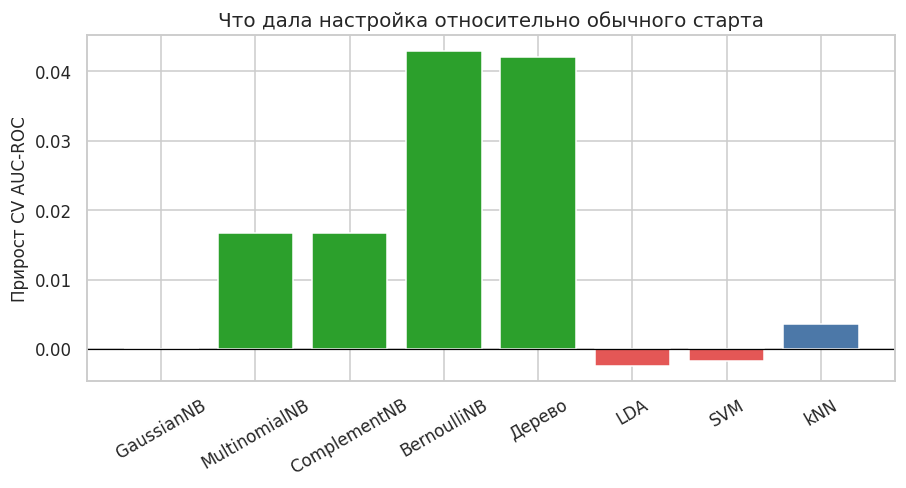


### Вывод по настройке в целом

Заметный прирост кросс-валидационного AUC-ROC (от 0.01 и выше) получен у: MultinomialNB (+0.0167), ComplementNB (+0.0167), BernoulliNB (+0.0429), Дерево (+0.0422).
Почти не сдвинулись относительно своего старта: GaussianNB (+0.0000), LDA (-0.0024), SVM (-0.0017), kNN (+0.0036).
Точки, которые формально хуже собственного старта больше чем на 0.002: нет.

Прирост от 0.01 означает, что стартовая точка была неудачной. У дерева это слишком мелкие листья, у Бернулли — порог, который выбрасывает контраст размера, у мультиномиальных моделей — выравнивание масштаба, заглушившее площадь. Околонулевой прирост означает другое: библиотечный старт уже лежал на верхней полке, и сетка не нашла существенно лучшего режима. Отрицательный сдвиг в несколько тысячных — это шум правила плоской вершины, а не поломка метода.

Эти AUC ещё немного оптимистичны. Точка выбрана как одна из лучших на той же кросс-валидации, по которой она оценена. Честная проверка — тестовая выборка в следующем разделе. Она не входила ни в одну строку таблицы выше.

Параметры, которые уходят в финал:

- **GaussianNB:** StandardScaler, var_smoothing=1e-03
- **MultinomialNB:** исходный масштаб, alpha=10
- **ComplementNB:** исходный масштаб, alpha=10
- **BernoulliNB:** MinMaxScaler, порог=0.3, alpha=1
- **Дерево:** depth=5, leaf=20, gini
- **LDA:** lsqr, shrinkage=0.5, StandardScaler
- **SVM:** linear, C=0.01, веса=обычные, StandardScaler
- **kNN:** k=24, uniform, euclidean, StandardScaler


In [13]:
order = ["GaussianNB", "MultinomialNB", "ComplementNB", "BernoulliNB", "Дерево", "LDA", "SVM", "kNN"]
tuning_table = pd.DataFrame([tuning_summary[name] for name in order]).set_index("Метод")
display(tuning_table.round(4))

fig, ax = plt.subplots(figsize=(8.4, 4.6))
gains = tuning_table["Прирост AUC"]
colors = ["#2CA02C" if value >= 0.01 else "#4C78A8" if value >= 0 else "#E45756" for value in gains]
ax.bar(gains.index, gains.values, color=colors)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Прирост CV AUC-ROC")
ax.set_title("Что дала настройка относительно обычного старта")
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()

big = tuning_table[tuning_table["Прирост AUC"] >= 0.01]
flat = tuning_table[tuning_table["Прирост AUC"].abs() < 0.005]
negative = tuning_table[tuning_table["Прирост AUC"] <= -0.005]

def listing(frame):
    if frame.empty:
        return "нет"
    return ", ".join(f"{idx} ({row['Прирост AUC']:+.4f})" for idx, row in frame.iterrows())

summary_text = f'''
### Вывод по настройке в целом

Заметный прирост кросс-валидационного AUC-ROC (от 0.01 и выше) получен у: {listing(big)}.
Почти не сдвинулись относительно своего старта: {listing(flat)}.
Точки, которые формально хуже собственного старта больше чем на 0.002: {listing(negative)}.

Прирост от 0.01 означает, что стартовая точка была неудачной. У дерева это слишком мелкие листья, у Бернулли — порог, который выбрасывает контраст размера, у мультиномиальных моделей — выравнивание масштаба, заглушившее площадь. Околонулевой прирост означает другое: библиотечный старт уже лежал на верхней полке, и сетка не нашла существенно лучшего режима. Отрицательный сдвиг в несколько тысячных — это шум правила плоской вершины, а не поломка метода.

Эти AUC ещё немного оптимистичны. Точка выбрана как одна из лучших на той же кросс-валидации, по которой она оценена. Честная проверка — тестовая выборка в следующем разделе. Она не входила ни в одну строку таблицы выше.

Параметры, которые уходят в финал:

{chr(10).join(f"- **{name}:** {best_configs[name]['params_text']}" for name in order)}
'''
display(Markdown(summary_text))

## 6. Сравнительный анализ

Выбранные конвейеры заново обучаются на всей обучающей выборке и один раз применяются к тесту. Для SVM на этом шаге включается `probability=True`: ROC и порог решения используют вероятности, а не сырую функцию отступа. Сетка по-прежнему не пересматривается.

Правило итогового выбора, зафиксированное до просмотра теста:

1. Ориентир ранжирования — AUC-ROC на тесте.
2. Если несколько методов отстают от лидера не больше чем на 0.01, между ними решает Recall злокачественного класса, затем F1. Пропуск опухоли важнее символического упрощения модели.
3. Более простая модель заменяет лидера по Recall только если она сама не хуже по полноте (разрыв меньше половины тестового случая) и при этом заметно проще: например LDA или линейный SVM вместо дерева, RBF или kNN. Две линейные модели с разницей в один найденный случай не усредняются: остаётся та, у которой меньше пропусков.

На 114 тестовых объектах сложная граница, выигравшая один случай у простой, легко меняется местами при другом разбиении. Поэтому в выводе верхняя группа описывается целиком, а не как единственный победитель с большим запасом.

### Метрики на тестовой выборке

Модели отсортированы по AUC-ROC, затем по Recall и F1. Столбец CV AUC-ROC — оценка выбранной точки на кросс-валидации; она слегка оптимистична, потому что точка выбиралась по этой же оценке.

,Accuracy,Precision,Recall,F1-Score,AUC-ROC,CV AUC-ROC
Метод,,,,,,
SVM,0.9561,1.0000,0.8810,0.9367,0.9980,0.9933
LDA,0.9474,1.0000,0.8571,0.9231,0.9980,0.9914
kNN,0.9474,1.0000,0.8571,0.9231,0.9959,0.9907
GaussianNB,0.9211,0.9231,0.8571,0.8889,0.9891,0.9870
BernoulliNB,0.9386,0.9487,0.8810,0.9136,0.9873,0.9832
Дерево,0.9386,0.9268,0.9048,0.9157,0.9785,0.9594
MultinomialNB,0.8947,0.9688,0.7381,0.8378,0.9458,0.9385
ComplementNB,0.8947,0.9688,0.7381,0.8378,0.9458,0.9386


### Параметры, с которыми модели вышли на тест

,Параметры
Метод,
SVM,"linear, C=0.01, веса=обычные, StandardScaler"
LDA,"lsqr, shrinkage=0.5, StandardScaler"
kNN,"k=24, uniform, euclidean, StandardScaler"
GaussianNB,"StandardScaler, var_smoothing=1e-03"
BernoulliNB,"MinMaxScaler, порог=0.3, alpha=1"
Дерево,"depth=5, leaf=20, gini"
MultinomialNB,"исходный масштаб, alpha=10"
ComplementNB,"исходный масштаб, alpha=10"


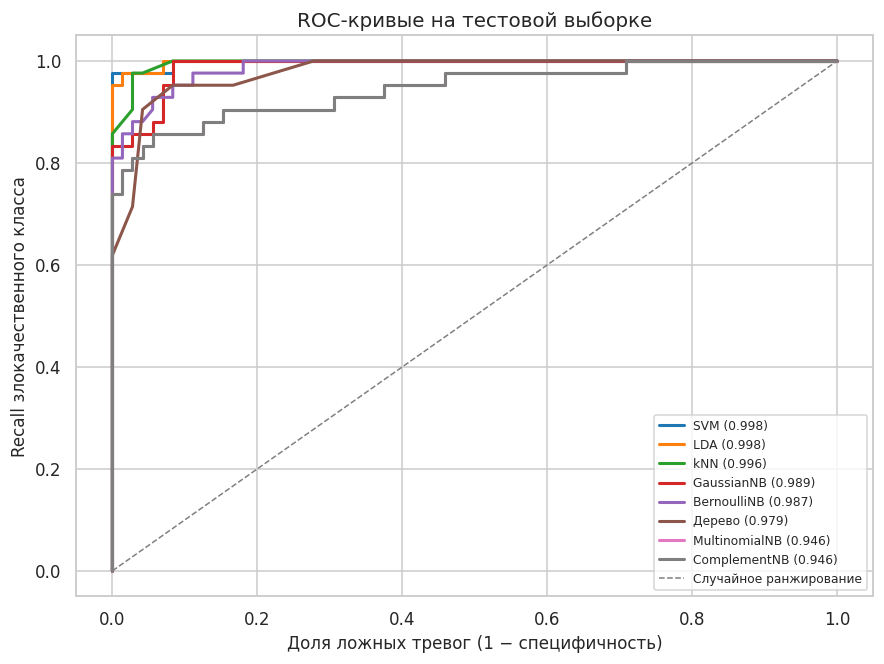

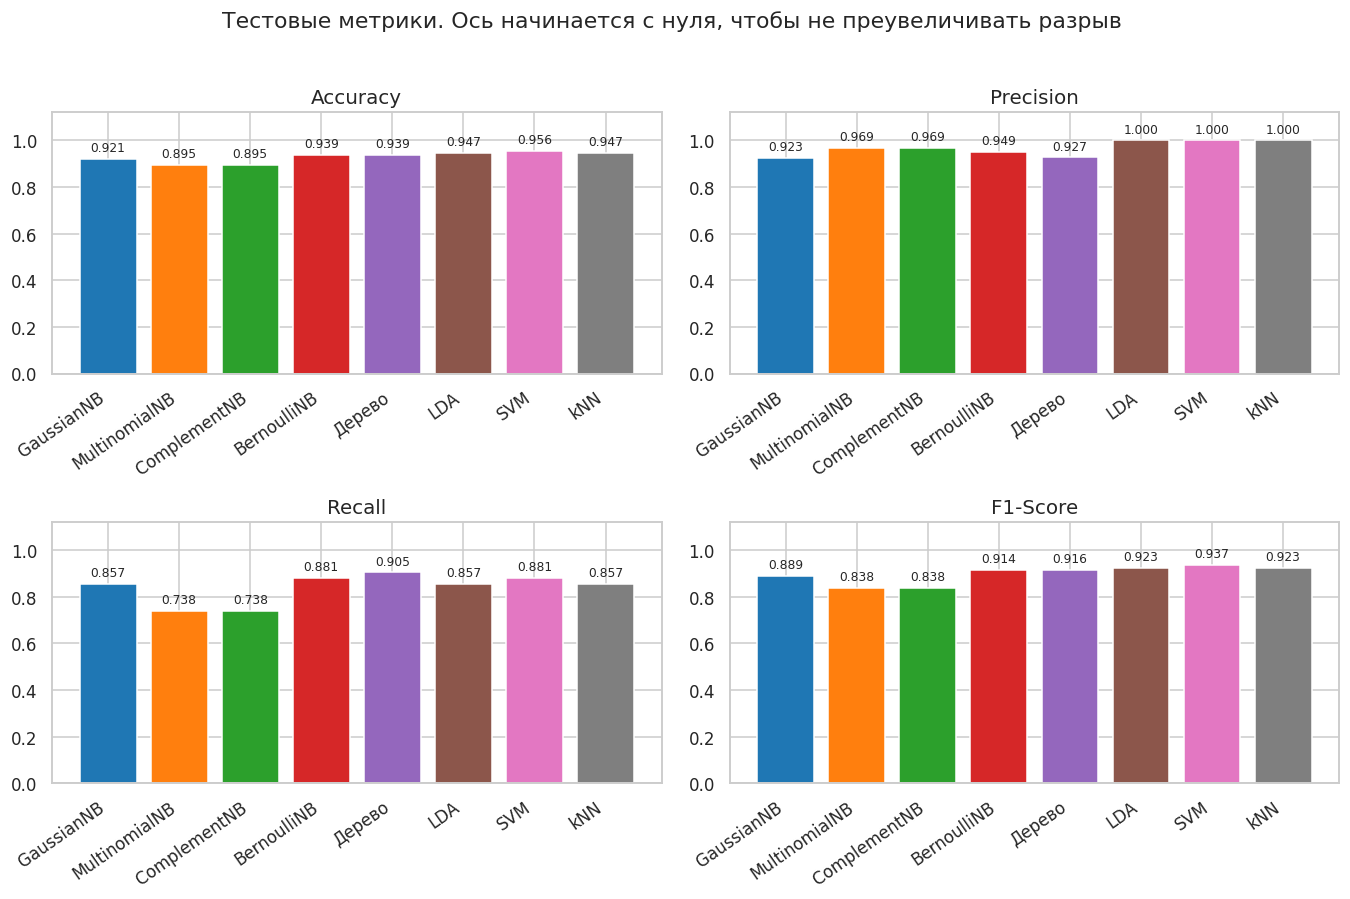

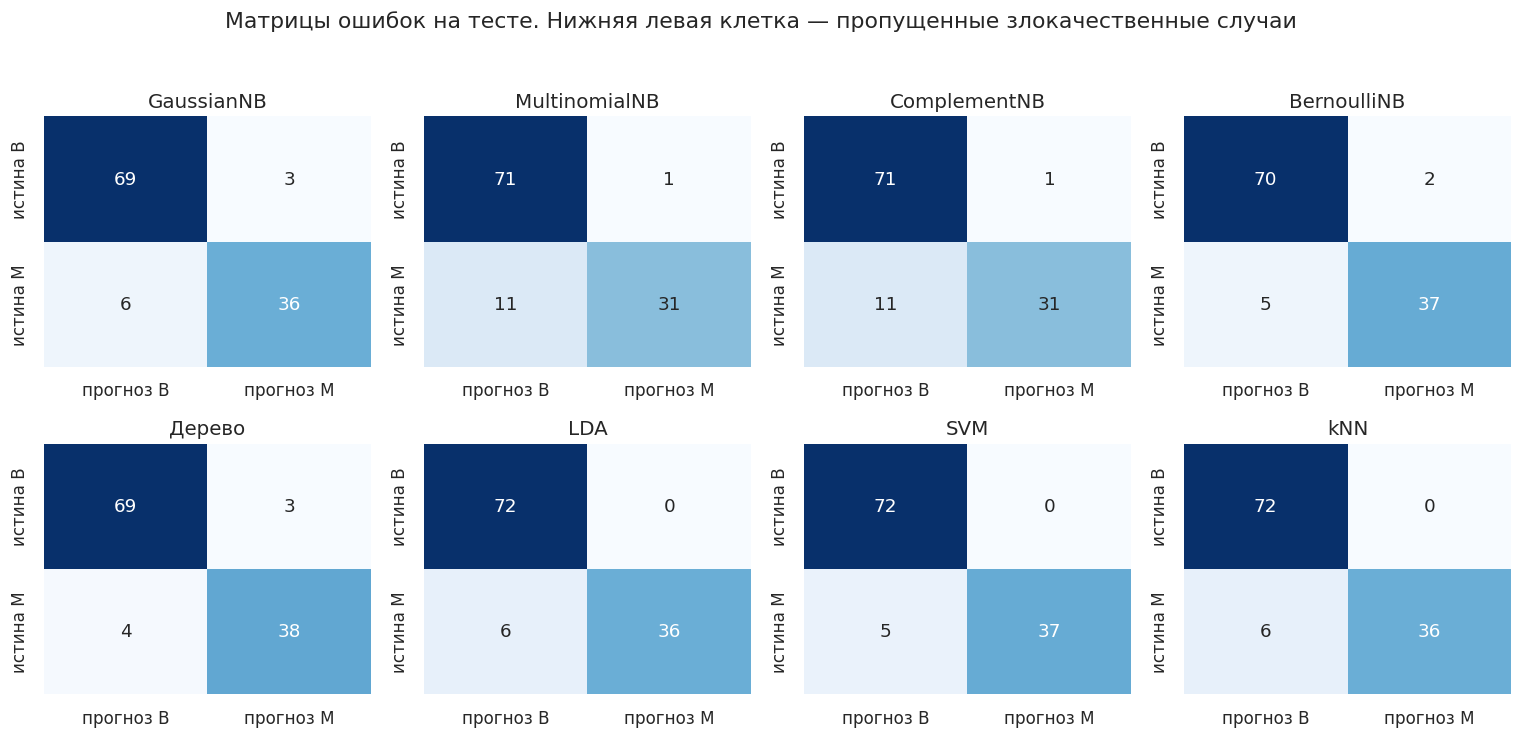


### Вывод по сравнению методов

Константа «всегда доброкачественная» дала бы на этом тесте Accuracy 0.632 и Recall 0. Все восемь настроенных моделей уверенно выше этой полки и по доле верных ответов, и по поиску злокачественных случаев.

Лидер по AUC-ROC внутри верхней группы совпадает с лучшим Recall: это **SVM**. AUC-ROC = 0.9980, Recall = 0.8810, Precision = 1.0000, F1 = 0.9367, Accuracy = 0.9561.

В полосе «не хуже лидера более чем на 0.01 по AUC-ROC» оказались: LDA (AUC 0.998, Recall 0.857), SVM (AUC 0.998, Recall 0.881), kNN (AUC 0.996, Recall 0.857), GaussianNB (AUC 0.989, Recall 0.857).

Второе место по AUC-ROC — LDA (0.9980). AUC-ROC лидера и второго места совпадает до четвёртого знака. Один пропущенный злокачественный случай меняет Recall на 0.024. Методы в верхней части таблицы расходятся на величину порядка одного-двух пациентов. Таблица показывает плотную группу сильных моделей, а не единственный алгоритм с большим запасом.

Рядом лежит **LDA**: AUC-ROC 0.9980, Recall 0.8571, пропусков 6 из 42, ложных тревог 0. У **SVM** пропусков 5. Разница — один тестовый случай. Обе модели линейные, поэтому дальше упрощать нечего. Остаётся та, которая находит больше злокачественных случаев при том же качестве ранжирования.

У рекомендуемой модели **SVM** на тесте 37 верно найденных злокачественных, 5 пропусков, 0 ложных тревог и 72 верно оставленных доброкачественных. Пропущено 5 из 42. Линейная полоса максимума зазора после стандартизации отделяет классы не хуже более гибких границ. Опорных векторов модели хватает, а лишняя ёмкость RBF не нужна.

Нижнюю полку делят **MultinomialNB** (AUC-ROC 0.9458, Recall 0.7381, F1 0.8378), **ComplementNB** (AUC-ROC 0.9458, Recall 0.7381, F1 0.8378). На тесте их метрики практически совпали. Эти модели описывают непрерывные измерения как неотрицательные частоты и не используют форму распределения внутри класса. Поправка ComplementNB на редкий класс ничего не добавила: при долях 63/37 злокачественных объектов и так достаточно, чтобы оценить средние.

Внутри байесовского семейства порядок по тестовому AUC-ROC такой: GaussianNB (0.989), BernoulliNB (0.987), MultinomialNB (0.946), ComplementNB (0.946). BernoulliNB (0.987) после подобранного порога почти не отстаёт от GaussianNB (0.989): главный контраст размера переживает перевод в 0/1. MultinomialNB (0.946) и ComplementNB (0.946) идут парой и остаются ниже. Схема частот хуже описывает эти измерения, а оценка по дополнению класса не меняет ответ.

Тестовый AUC-ROC не ниже кросс-валидационного. На 114 объектах так бывает из-за удачного состава теста. Завышать метод из-за одного удачного разбиения не стоит, но и провала обобщения нет.

Настройка из раздела 5 и место в тестовой таблице не обязаны совпадать. Удачный порог или ограничение глубины поднимают слабый старт, но не делают мультиномиальную модель линейной. Сначала отбрасываются методы, чьи предпосылки режут сигнал: на этих данных это описание измерений как частот. Затем среди линейных моделей с близким AUC берётся та, у которой меньше пропусков злокачественных случаев.

**Итоговая рекомендация для этого датасета — SVM** с параметрами `linear, C=0.01, веса=обычные, StandardScaler`. На тесте у неё Accuracy 0.9561, Precision 1.0000, Recall 0.8810, F1-Score 0.9367, AUC-ROC 0.9980.

Оговорки, без которых рекомендацию легко переоценить. Тест состоит из 114 объектов, злокачественных среди них 42. Другое случайное разбиение может поменять местами SVM, LDA и kNN внутри верхней группы. Соотношение кросс-валидации и теста для этого разбиения приведено выше и не заменяет повторную проверку. Признаки размера сильно коррелированы, и любой метод, который считает их независимыми, завышает свою уверенность. Слабые признаки вроде части фрактальных оценок не отбирались: сравнение шло на полном наборе. Наконец, это архив оцифрованных пункций одного исследовательского источника, а не поток обследований из нескольких клиник. Вывод отвечает на вопрос, какой алгоритм лучше описывает эту таблицу, и не является клиническим решением.


In [14]:
fitted = {}
test_rows = []
scores = {}
predictions = {}
cms = {}

for name in order:
    model = build(best_configs[name], probability=True)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    score = model.predict_proba(X_test)[:, 1]
    fitted[name] = model
    scores[name] = score
    predictions[name] = pred
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    cms[name] = {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}
    test_rows.append(
        {
            "Метод": name,
            "Accuracy": accuracy_score(y_test, pred),
            "Precision": precision_score(y_test, pred, pos_label=1, zero_division=0),
            "Recall": recall_score(y_test, pred, pos_label=1, zero_division=0),
            "F1-Score": f1_score(y_test, pred, pos_label=1, zero_division=0),
            "AUC-ROC": roc_auc_score(y_test, score),
            "CV AUC-ROC": best_configs[name]["cv_roc_auc"],
        }
    )

report = pd.DataFrame(test_rows).set_index("Метод").loc[order]
report_sorted = report.sort_values(["AUC-ROC", "Recall", "F1-Score"], ascending=False)

display(Markdown("### Метрики на тестовой выборке"))
display(Markdown(
    "Модели отсортированы по AUC-ROC, затем по Recall и F1. "
    "Столбец CV AUC-ROC — оценка выбранной точки на кросс-валидации; она слегка оптимистична, потому что точка выбиралась по этой же оценке."
))
display(report_sorted.round(4))

params_view = pd.DataFrame(
    {"Параметры": [best_configs[name]["params_text"] for name in report_sorted.index]},
    index=report_sorted.index,
)
display(Markdown("### Параметры, с которыми модели вышли на тест"))
display(params_view)

fig, ax = plt.subplots(figsize=(8.2, 6.2))
palette = sns.color_palette("tab10", n_colors=len(report_sorted))
for color, name in zip(palette, report_sorted.index):
    fpr, tpr, _ = roc_curve(y_test, scores[name])
    ax.plot(fpr, tpr, color=color, linewidth=2, label=f"{name} ({report_sorted.loc[name, 'AUC-ROC']:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1, label="Случайное ранжирование")
ax.set_xlabel("Доля ложных тревог (1 − специфичность)")
ax.set_ylabel("Recall злокачественного класса")
ax.set_title("ROC-кривые на тестовой выборке")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()

metric_names = ["Accuracy", "Precision", "Recall", "F1-Score"]
fig, axes = plt.subplots(2, 2, figsize=(12.5, 8))
for ax, metric in zip(axes.ravel(), metric_names):
    values = report.loc[order, metric]
    ax.bar(np.arange(len(order)), values.values, color=sns.color_palette("tab10", n_colors=len(order)))
    ax.set_xticks(np.arange(len(order)))
    ax.set_xticklabels(order, rotation=35, ha="right")
    ax.set_ylim(0, 1.12)
    ax.set_title(metric)
    for i, value in enumerate(values.values):
        ax.text(i, value + 0.02, f"{value:.3f}", ha="center", va="bottom", fontsize=8)
fig.suptitle("Тестовые метрики. Ось начинается с нуля, чтобы не преувеличивать разрыв", y=1.02)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(14, 6.5))
for ax, name in zip(axes.ravel(), order):
    matrix = np.array([[cms[name]["tn"], cms[name]["fp"]], [cms[name]["fn"], cms[name]["tp"]]])
    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cbar=False,
        cmap="Blues",
        ax=ax,
        xticklabels=["прогноз B", "прогноз M"],
        yticklabels=["истина B", "истина M"],
    )
    ax.set_title(name)
fig.suptitle("Матрицы ошибок на тесте. Нижняя левая клетка — пропущенные злокачественные случаи", y=1.03)
fig.tight_layout()
plt.show()

leader_name = report_sorted.index[0]
leader = report_sorted.iloc[0]
close = report[report["AUC-ROC"] >= leader["AUC-ROC"] - 0.01].copy()
practical = close.sort_values(["Recall", "F1-Score", "AUC-ROC"], ascending=False)
practical_name = practical.index[0]
second_name = report_sorted.index[1]
second = report_sorted.iloc[1]
weak_name = report_sorted.index[-1]
weak = report_sorted.iloc[-1]

simplicity = {
    "LDA": 0,
    "GaussianNB": 1,
    "SVM": 2 if best_configs["SVM"]["params"]["kernel"] == "linear" else 5,
    "MultinomialNB": 3,
    "ComplementNB": 3,
    "BernoulliNB": 4,
    "kNN": 6,
    "Дерево": 6,
}
simple_pool = close.copy()
simple_pool["простота"] = [simplicity[name] for name in simple_pool.index]
simple_pool = simple_pool.sort_values(["простота", "Recall", "AUC-ROC"], ascending=[True, False, False])
simple_name = simple_pool.index[0]

def case_gap(name_a, name_b, metric):
    return abs(float(report.loc[name_a, metric] - report.loc[name_b, metric])) * (
        n_pos_test if metric == "Recall" else n_test
    )

auc_gap = float(leader["AUC-ROC"] - second["AUC-ROC"])
recall_cases = abs(float(report.loc[leader_name, "Recall"] - report.loc[practical_name, "Recall"])) * n_pos_test

why = {
    "GaussianNB": "Гауссовские портреты отдельных признаков уже разделяют классы. Зависимость радиуса, периметра и площади методу мешает теоретически, но маргинальный сдвиг средних, который был виден по Cohen's d, перекрывает эту ошибку модели.",
    "MultinomialNB": "Мультиномиальная схема для этих измерений теоретически чужая, но после выбранного масштаба относительный вклад признаков оказался достаточным, чтобы обойти модели с более честными предпосылками. Такой результат стоит читать осторожно: он завязан на предобработку, а не на то, что ядра клетки порождают счётчики.",
    "ComplementNB": "Оценка по дополнению класса лучше прямой мультиномиальной оценки на этом умеренном дисбалансе. Содержательно это всё ещё байесовская модель неотрицательных признаков, а не описание формы ядра.",
    "BernoulliNB": "Грубого факта «признак выше порога своего диапазона» оказалось достаточно. Классы разделены так явно, что величина отклонения почти не нужна. Это свойство данных, а не доказательство, что бинаризация вообще безвредна.",
    "Дерево": "Нескольких порогов по размеру и форме контура хватает, чтобы собрать кусочную границу. Дерево выигрывает там, где взаимодействие признаков важнее общей линейной комбинации. Платой остаётся более шумная граница и больший разрыв обучения с проверкой, если глубина не ограничена.",
    "LDA": "Общая ковариация и подобранное сжатие хорошо ложатся на задачу: классы похожи на два эллипсоида, сдвинутых по размеру и вогнутости. Линейной оси достаточно, а shrinkage гасит тройной учёт радиуса, периметра и площади.",
    "SVM": (
        "Линейная полоса максимума зазора после стандартизации отделяет классы не хуже более гибких границ. Опорных векторов модели хватает, а лишняя ёмкость RBF не нужна."
        if best_configs["SVM"]["params"]["kernel"] == "linear"
        else "Ядру RBF удаётся повторить изгиб границы там, где одной гиперплоскости мало. Это выигрыш ёмкости, и его нужно держать рядом с риском подгонки под 455 обучающих объектов."
    ),
    "kNN": "Локальный состав окрестности в стандартизованном пространстве совпадает с классом лучше, чем одна глобальная формула. Метод не предполагает гауссовость и не строит плоскость. Он проигрывает в интерпретации: ответ нельзя записать как вклад признаков, его можно только показать соседями.",
}
why_weak = {
    "GaussianNB": "Нормальность и независимость здесь слишком грубы, и модель проигрывает тем, кто умеет учитывать совместное распределение или локальную геометрию.",
    "MultinomialNB": "Непрерывные измерения плохо заменяются мультиномиальными частотами. Даже после выравнивания масштаба модель не использует форму распределения внутри класса.",
    "ComplementNB": "Поправка на редкий класс не компенсирует чужую для этих чисел вероятностную схему.",
    "BernoulliNB": "Бинаризация выбрасывает, насколько признак велик. На перекрывающихся хвостах распределений, которые было видно на ящиках с усами, именно величина отделяет классы.",
    "Дерево": "Кусочно-постоянная граница на небольшой выборке дробит пространство раньше, чем набирает статистику в листьях. Линейные методы используют все 30 координат сразу и поэтому устойчивее.",
    "LDA": "Общая ковариация и линейная ось не описывают границу. Данным нужен изгиб или локальное правило, которого у LDA нет.",
    "SVM": "Полоса зазора не попала в форму классов. Либо ядро слишком жёсткое, либо регуляризация C не совпала с масштабом шума.",
    "kNN": "В 30-мерном пространстве окрестность уже разрежена. Соседи находятся формально близко по метрике, но состав окна шумный, и голосование проигрывает глобальной модели.",
}

nb_order = report.loc[["GaussianNB", "MultinomialNB", "ComplementNB", "BernoulliNB"]].sort_values("AUC-ROC", ascending=False)
nb_best, nb_worst = nb_order.index[0], nb_order.index[-1]

def beats_majority(name):
    return float(report.loc[name, "Accuracy"]) > majority_acc + 0.05 and float(report.loc[name, "Recall"]) > 0

all_beat = all(beats_majority(name) for name in order)
baseline_comment = (
    f"Константа «всегда доброкачественная» дала бы на этом тесте Accuracy {majority_acc:.3f} и Recall 0. "
    + (
        "Все восемь настроенных моделей уверенно выше этой полки и по доле верных ответов, и по поиску злокачественных случаев."
        if all_beat
        else "Не каждая модель далеко уходит от этой полки. Те, у кого Recall близок к нулю или Accuracy едва выше доли класса B, для задачи не годятся, каким бы ни был их ранг в таблице."
    )
)

cv_gaps = report["CV AUC-ROC"] - report["AUC-ROC"]
optimistic = cv_gaps.sort_values(ascending=False).head(1)
opt_name = optimistic.index[0]
opt_value = float(optimistic.iloc[0])
if opt_value > 0.03:
    cv_comment = (
        f"Сильнее всего кросс-валидация оптимистичнее теста у метода {opt_name}: разрыв {opt_value:.4f}. "
        "Выбор максимума по сетке подрисовал оценку, а конкретное разбиение теста оказалось труднее фолдов."
    )
elif opt_value < 0:
    cv_comment = (
        "Тестовый AUC-ROC не ниже кросс-валидационного. На 114 объектах так бывает из-за удачного состава теста. "
        "Завышать метод из-за одного удачного разбиения не стоит, но и провала обобщения нет."
    )
else:
    cv_comment = (
        f"Самый большой разрыв «CV минус тест» равен {opt_value:.4f} ({opt_name}). "
        "Это меньше трёх сотых: выбранные модели не развалились на данных, которые сетка не видела."
    )

if practical_name == leader_name:
    choice_comment = (
        f"Лидер по AUC-ROC внутри верхней группы совпадает с лучшим Recall: это **{leader_name}**. "
        f"AUC-ROC = {leader['AUC-ROC']:.4f}, Recall = {leader['Recall']:.4f}, "
        f"Precision = {leader['Precision']:.4f}, F1 = {leader['F1-Score']:.4f}, "
        f"Accuracy = {leader['Accuracy']:.4f}."
    )
else:
    choice_comment = (
        f"Формальный лидер по AUC-ROC — **{leader_name}** ({leader['AUC-ROC']:.4f}, "
        f"Recall {leader['Recall']:.4f}). Внутри полосы 0.01 выше полнота у **{practical_name}**: "
        f"Recall {report.loc[practical_name, 'Recall']:.4f}. "
        "Дальше рекомендация опирается на полноту, потому что пропуск злокачественного случая тяжелее небольшого выигрыша в ранжировании."
    )

recommend_name = practical_name
if simple_name != practical_name:
    simple_recall_gap_cases = abs(
        float(report.loc[simple_name, "Recall"] - report.loc[practical_name, "Recall"])
    ) * n_pos_test
    simple_auc_gap = abs(float(report.loc[simple_name, "AUC-ROC"] - report.loc[practical_name, "AUC-ROC"]))
    practical_is_complex = simplicity[practical_name] >= 5
    simpler_recall_not_worse = float(report.loc[simple_name, "Recall"]) + 1e-9 >= float(
        report.loc[practical_name, "Recall"]
    )
    if practical_is_complex and simple_auc_gap <= 0.01 and simple_recall_gap_cases <= 1 and simpler_recall_not_worse:
        recommend_name = simple_name
        recommend_comment = (
            f"В той же полосе AUC более простая модель **{simple_name}** "
            f"(AUC-ROC {report.loc[simple_name, 'AUC-ROC']:.4f}, Recall {report.loc[simple_name, 'Recall']:.4f}) "
            f"не уступает {practical_name} по полноте. Берётся она: сложность дерева, RBF или kNN здесь не оплачена."
        )
    elif simplicity[practical_name] <= 2:
        if round(simple_recall_gap_cases) == 1:
            gap_phrase = "Разница — один тестовый случай."
        else:
            gap_phrase = f"Разница — около {simple_recall_gap_cases:.1f} тестового случая."
        recommend_comment = (
            f"Рядом лежит **{simple_name}**: AUC-ROC {report.loc[simple_name, 'AUC-ROC']:.4f}, "
            f"Recall {report.loc[simple_name, 'Recall']:.4f}, "
            f"пропусков {cms[simple_name]['fn']} из {n_pos_test}, ложных тревог {cms[simple_name]['fp']}. "
            f"У **{practical_name}** пропусков {cms[practical_name]['fn']}. {gap_phrase} "
            "Обе модели линейные, поэтому дальше упрощать нечего. Остаётся та, которая находит больше злокачественных случаев при том же качестве ранжирования."
        )
    else:
        recommend_comment = (
            f"Более простая {simple_name} уступает по Recall примерно на {simple_recall_gap_cases:.1f} случая, "
            f"поэтому остаётся **{practical_name}**."
        )
else:
    recommend_comment = (
        f"Модель **{recommend_name}** одновременно лучшая по полноте в верхней группе и не сложнее её остальных участников."
    )

cm = cms[recommend_name]
cm_text = (
    f"У рекомендуемой модели **{recommend_name}** на тесте {cm['tp']} верно найденных злокачественных, "
    f"{cm['fn']} пропусков, {cm['fp']} ложных тревог и {cm['tn']} верно оставленных доброкачественных. "
    f"Пропущено {cm['fn']} из {n_pos_test}."
)

close_names = ", ".join(
    f"{idx} (AUC {row['AUC-ROC']:.3f}, Recall {row['Recall']:.3f})"
    for idx, row in close.sort_values("AUC-ROC", ascending=False).iterrows()
)

second_cases = abs(float(leader["Recall"] - second["Recall"])) * n_pos_test
if auc_gap < 0.0005:
    noise_comment = (
        f"Второе место по AUC-ROC — {second_name} ({second['AUC-ROC']:.4f}). "
        "AUC-ROC лидера и второго места совпадает до четвёртого знака. "
    )
else:
    noise_comment = (
        f"Второе место по AUC-ROC — {second_name} ({second['AUC-ROC']:.4f}). "
        f"Отрыв лидера {auc_gap:.4f} по AUC. "
    )
if auc_gap < 0.01 or second_cases < 2:
    noise_comment += (
        f"Один пропущенный злокачественный случай меняет Recall на {recall_unit:.3f}. "
        "Методы в верхней части таблицы расходятся на величину порядка одного-двух пациентов. "
        "Таблица показывает плотную группу сильных моделей, а не единственный алгоритм с большим запасом."
    )
else:
    noise_comment += "Отрыв уже больше типичного шума одного-двух тестовых случаев, его можно обсуждать как содержательный."

weak_band = report[report["AUC-ROC"] <= float(weak["AUC-ROC"]) + 0.001]
if len(weak_band) > 1:
    weak_list = ", ".join(
        f"**{idx}** (AUC-ROC {row['AUC-ROC']:.4f}, Recall {row['Recall']:.4f}, F1 {row['F1-Score']:.4f})"
        for idx, row in weak_band.sort_values("AUC-ROC", ascending=False).iterrows()
    )
    weak_text = (
        f"Нижнюю полку делят {weak_list}. На тесте их метрики практически совпали. "
        "Эти модели описывают непрерывные измерения как неотрицательные частоты и не используют форму распределения внутри класса. "
        "Поправка ComplementNB на редкий класс ничего не добавила: при долях 63/37 злокачественных объектов и так достаточно, чтобы оценить средние."
    )
else:
    weak_text = (
        f"Слабее всех на тесте по AUC-ROC — **{weak_name}** "
        f"({weak['AUC-ROC']:.4f}, Recall {weak['Recall']:.4f}, F1 {weak['F1-Score']:.4f}). {why_weak[weak_name]}"
    )

gauss_auc_test = float(report.loc["GaussianNB", "AUC-ROC"])
bern_auc_test = float(report.loc["BernoulliNB", "AUC-ROC"])
multi_auc_test = float(report.loc["MultinomialNB", "AUC-ROC"])
comp_auc_test = float(report.loc["ComplementNB", "AUC-ROC"])
bayes_order_text = ", ".join(f"{idx} ({row['AUC-ROC']:.3f})" for idx, row in nb_order.iterrows())
if abs(gauss_auc_test - bern_auc_test) < 0.015:
    bern_clause = (
        f"BernoulliNB ({bern_auc_test:.3f}) после подобранного порога почти не отстаёт от GaussianNB ({gauss_auc_test:.3f}): "
        "главный контраст размера переживает перевод в 0/1."
    )
else:
    bern_clause = (
        f"BernoulliNB ({bern_auc_test:.3f}) заметно ниже GaussianNB ({gauss_auc_test:.3f}): "
        "порог выбрасывает, насколько именно ядро больше."
    )
if abs(multi_auc_test - comp_auc_test) < 0.002:
    multi_clause = (
        f"MultinomialNB ({multi_auc_test:.3f}) и ComplementNB ({comp_auc_test:.3f}) идут парой и остаются ниже. "
        "Схема частот хуже описывает эти измерения, а оценка по дополнению класса не меняет ответ."
    )
else:
    multi_clause = (
        f"MultinomialNB ({multi_auc_test:.3f}) и ComplementNB ({comp_auc_test:.3f}) оба ниже гауссовской модели. "
        "Неотрицательная «масса» признака — более бедное описание, чем нормальная плотность."
    )
bayes_comment = (
    f"Внутри байесовского семейства порядок по тестовому AUC-ROC такой: {bayes_order_text}. "
    f"{bern_clause} {multi_clause}"
)

final_text = f'''
### Вывод по сравнению методов

{baseline_comment}

{choice_comment}

В полосе «не хуже лидера более чем на 0.01 по AUC-ROC» оказались: {close_names}.

{noise_comment}

{recommend_comment}

{cm_text} {why[recommend_name]}

{weak_text}

{bayes_comment}

{cv_comment}

Настройка из раздела 5 и место в тестовой таблице не обязаны совпадать. Удачный порог или ограничение глубины поднимают слабый старт, но не делают мультиномиальную модель линейной. Сначала отбрасываются методы, чьи предпосылки режут сигнал: на этих данных это описание измерений как частот. Затем среди линейных моделей с близким AUC берётся та, у которой меньше пропусков злокачественных случаев.

**Итоговая рекомендация для этого датасета — {recommend_name}** с параметрами `{best_configs[recommend_name]['params_text']}`. На тесте у неё Accuracy {report.loc[recommend_name, 'Accuracy']:.4f}, Precision {report.loc[recommend_name, 'Precision']:.4f}, Recall {report.loc[recommend_name, 'Recall']:.4f}, F1-Score {report.loc[recommend_name, 'F1-Score']:.4f}, AUC-ROC {report.loc[recommend_name, 'AUC-ROC']:.4f}.

Оговорки, без которых рекомендацию легко переоценить. Тест состоит из {n_test} объектов, злокачественных среди них {n_pos_test}. Другое случайное разбиение может поменять местами SVM, LDA и kNN внутри верхней группы. Соотношение кросс-валидации и теста для этого разбиения приведено выше и не заменяет повторную проверку. Признаки размера сильно коррелированы, и любой метод, который считает их независимыми, завышает свою уверенность. Слабые признаки вроде части фрактальных оценок не отбирались: сравнение шло на полном наборе. Наконец, это архив оцифрованных пункций одного исследовательского источника, а не поток обследований из нескольких клиник. Вывод отвечает на вопрос, какой алгоритм лучше описывает эту таблицу, и не является клиническим решением.
'''
display(Markdown(final_text))